# RL architectures and fitting protocols — published-code update

Published source: [Eckstein et al., Nature Human Behaviour (2026)](https://doi.org/10.1038/s41562-025-02324-0), supplied as `s41562-025-02324-0-2.pdf`. Code pinned to [`baf38da49fd1c1537affbc3745e961bbf0ae547d`](https://github.com/google-deepmind/hybrid_rnns_reward_learning/tree/baf38da49fd1c1537affbc3745e961bbf0ae547d). The article and code differ in several details; the distinctions below are deliberate. Restart the kernel before using the updated modules. Previous source/notebook versions are archived under `results/model_implementation_archive/pre_release_alignment_*`; existing result directories are preserved.

This notebook contains three distinctly labelled RL models:

| Model key | Model | Parameters |
|---|---|---|
| `sticky_rl` | Original Q-learning plus nonnegative stickiness | learning_rate, beta, alpha (stickiness) |
| `best_rl` | Six-parameter **written-paper** Best RL | learning_rate, beta, kappa, bias, forgetting, q_init |
| `released_rl` | Five-parameter **released CogMod example** | learning_rate, beta, kappa, forgetting, q_init |

The released example requests `fit_bias=True`, but the CogMod implementation never reads this flag or creates a bias parameter. Its persistent perseverance is also disabled. We preserve the six-parameter equations as a separate model, and add the actual five-parameter released computation. These are not silently treated as interchangeable.

The paper's α is `learning_rate`; the original notebook's `alpha` is stickiness (paper κ). `beta` is inverse temperature. The optimizer learning rate changes fitted parameters between batches; behavioral learning rate changes Q within sessions.

The original synthetic recovery and per-mouse leave-one-problem-out L-BFGS-B sections remain available. They minimize proper choice NLL over **all** choices. The final population section uses the released AdamW/shifted-loss protocol, fits shared parameters across training mice and tests on unseen mice. It omits first choices, so its metrics cannot be directly equated with the per-mouse protocol. The final section documents the paper/code disagreements, remaining mouse-task adaptations and separate proper versus release-proxy scores.

Only the new population section needs JAX/Optax. Load the audited cohort setup/data cells before cohort fitting; the large synthetic factorial sweep is independent. Full sweeps are opt-in.


In [20]:
from src.agents.mouse_agents import *
from src.tasks.drifting_bandit import *
import numpy as np
import matplotlib.pyplot as plt

In [21]:
# Define the parameters and structure of the task
num_trials = 1000
arms = [0, 1, 4]
num_arms = 3
drift_rate = 0.1
swap_mode = "most_chosen"  # "random" or "most_chosen" (among nonzero arms)

# Define the parameters for the mouse
learning_rate = 0.05
alpha = 0.25
beta = 2

bandit_task = DriftingBanditTask(arms, drift_rate=drift_rate, swap_mode=swap_mode)
mouse = QLearningMouse(num_arms, learning_rate, beta, alpha)
actions, rewards, q_values = bandit_task.simulate(mouse, num_trials)
# Available reward for each arm on every trial (trials x arms).
trial_groups = np.asarray(bandit_task.arm_history)


In [22]:
from pathlib import Path


def plot_summary_q_actions_figure(
    trial_groups, num_trials, snippet, actions, rewards, q_values, save_path=None
):
    """Plot available rewards/choices and post-update Q-values for one session.

    trial_groups and q_values have shape (num_trials, num_arms).
    actions contains zero-based arm indices. snippet selects the first trials;
    use None for the full session. save_path is a base path for PNG/PDF files.
    """
    magnitudes = np.asarray(trial_groups, dtype=float)
    q = np.asarray(q_values, dtype=float)
    choices = np.asarray(actions)
    received = np.asarray(rewards, dtype=float)
    if not isinstance(num_trials, (int, np.integer)) or num_trials <= 0:
        raise ValueError("num_trials must be a positive integer.")
    if magnitudes.ndim != 2 or magnitudes.shape[0] != num_trials or magnitudes.shape[1] == 0:
        raise ValueError("trial_groups must have shape (num_trials, num_arms).")
    if q.shape != magnitudes.shape:
        raise ValueError("q_values must have the same shape as trial_groups.")
    if choices.shape != (num_trials,) or received.shape != (num_trials,):
        raise ValueError("actions and rewards must each contain num_trials entries.")
    if not np.issubdtype(choices.dtype, np.integer) or np.any(
        (choices < 0) | (choices >= magnitudes.shape[1])
    ):
        raise ValueError("actions must contain valid zero-based arm indices.")
    if not np.allclose(received, magnitudes[np.arange(num_trials), choices]):
        raise ValueError("rewards do not match the chosen arms in trial_groups.")
    if snippet is not None and (
        not isinstance(snippet, (int, np.integer)) or snippet <= 0
    ):
        raise ValueError("snippet must be a positive integer or None.")

    n = num_trials if snippet is None else min(snippet, num_trials)
    trials = np.arange(1, n + 1)
    colors = ["#A6CEE3", "#FDBF6F", "#B2DF8A"]
    fig, (ax_rewards, ax_q) = plt.subplots(
        2, 1, figsize=(14, 7), sharex=True, layout="constrained"
    )
    for arm in range(magnitudes.shape[1]):
        color = colors[arm % len(colors)]
        ax_rewards.step(trials, magnitudes[:n, arm], where="mid",
                        color=color, linewidth=2.5, label=f"Arm {arm + 1}")
        ax_q.plot(trials, q[:n, arm], color=color, linewidth=2,
                  label=f"Arm {arm + 1}")
    ax_rewards.scatter(trials, received[:n], color="black", s=25,
                       zorder=5, label="Choice / received reward")

    # Mark changes in which arm is zero, between the affected trials.
    zero_changed = np.any(
        (magnitudes[1:n] == 0) != (magnitudes[:n - 1] == 0), axis=1
    )
    for j, boundary in enumerate(np.flatnonzero(zero_changed) + 1.5):
        for ax in (ax_rewards, ax_q):
            ax.axvline(boundary, color="0.55", linestyle="--", alpha=0.6,
                       linewidth=1, label="Zero-arm swap" if j == 0 else None)

    ax_rewards.set_title(f"Model session — first {n} of {num_trials} trials")
    ax_rewards.set_ylabel("Reward magnitude")
    ax_rewards.set_yticks([0, 1, 2, 3, 4])
    ax_q.set_ylabel("Q-value (after update)")
    ax_q.set_xlabel("Trial")
    ax_q.set_xlim(0.5, n + 0.5)
    for ax in (ax_rewards, ax_q):
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(loc="upper left", ncol=5, fontsize=9)
    if save_path is not None:
        base = Path(save_path)
        base.parent.mkdir(parents=True, exist_ok=True)
        for extension in ("png", "pdf"):
            fig.savefig(f"{base}.{extension}", dpi=300, bbox_inches="tight")
    plt.show()
    return fig, (ax_rewards, ax_q)


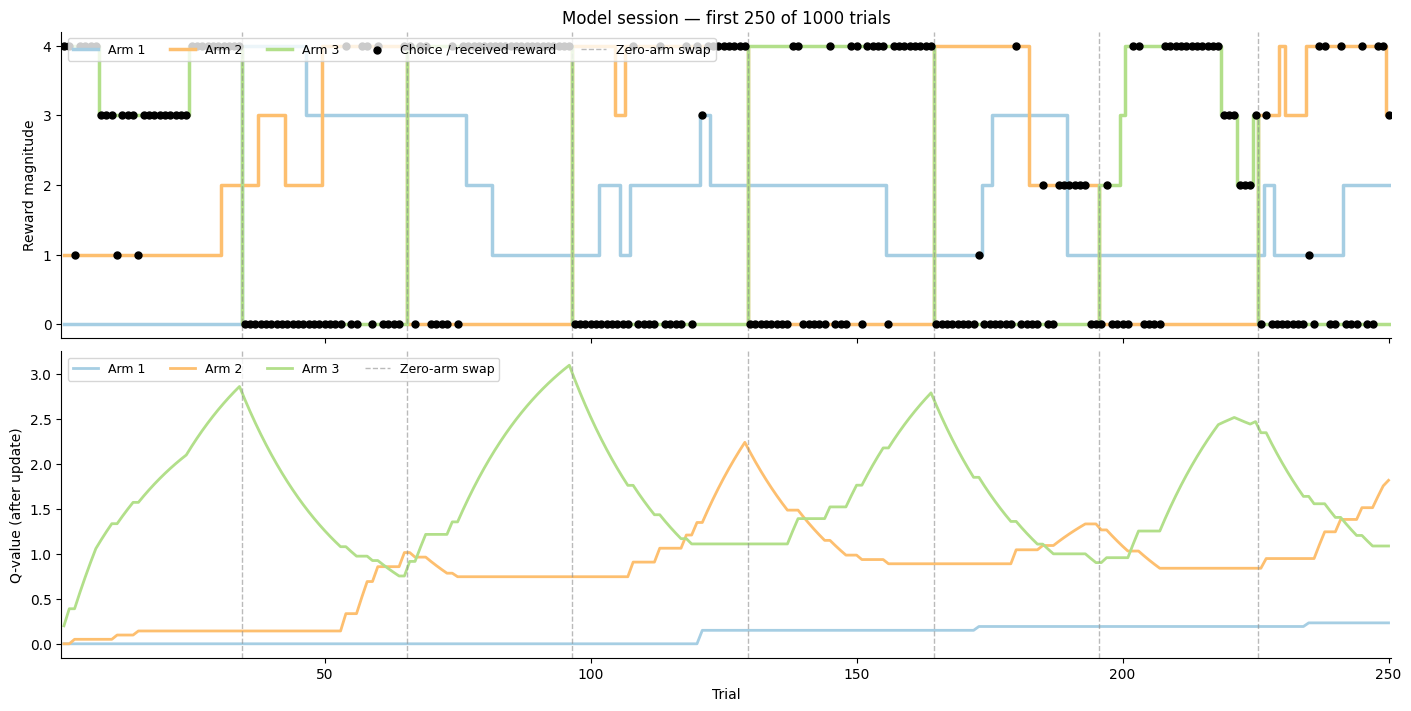

(<Figure size 1400x700 with 2 Axes>,
 (<Axes: title={'center': 'Model session — first 250 of 1000 trials'}, ylabel='Reward magnitude'>,
  <Axes: xlabel='Trial', ylabel='Q-value (after update)'>))

In [23]:
# Plot the relevant values
snippet = 250
# save_path
plot_summary_q_actions_figure(trial_groups, num_trials, snippet, actions, rewards, q_values)

## Synthetic parameter recovery
Fit the recorded choices and rewards while keeping the dataset fixed. Each candidate parameter set reconstructs its own Q-values from zero. Choice probabilities are evaluated **before** each reward update; saved post-update `q_values` are not used for fitting.

The loss is mean negative log choice probability (cross entropy). Multiple optimisation starts reduce sensitivity to local minima. The example bounds assume nonnegative stickiness.

In [24]:
import random
import pandas as pd
from scipy.optimize import minimize
from scipy.special import logsumexp

PARAMETER_NAMES = ["learning_rate", "beta", "alpha"]
PARAMETER_BOUNDS = [(0.001, 1.0), (0.01, 10.0), (0.0, 3.0)]

def choice_cross_entropy(params, actions, rewards, num_arms=3):
    learning_rate, beta, alpha = params
    q = np.zeros(num_arms)
    preferences = np.empty((len(actions), num_arms))
    previous_action = None
    for t, (action, reward) in enumerate(zip(actions, rewards)):
        preferences[t] = q
        if previous_action is not None:
            preferences[t, previous_action] += alpha
        q[action] += learning_rate * (reward - q[action])
        previous_action = action
    logits = beta * preferences
    return np.mean(logsumexp(logits, axis=1) - logits[np.arange(len(actions)), actions])


def fit_parameters(actions, rewards, num_arms=3, n_starts=10, seed=0):
    actions = np.asarray(actions)
    rewards = np.asarray(rewards, dtype=float)
    if actions.ndim != 1 or rewards.shape != actions.shape or len(actions) == 0:
        raise ValueError("actions and rewards must be equally sized, nonempty 1D arrays.")
    if (not np.issubdtype(actions.dtype, np.integer)
            or np.any(actions < 0) or np.any(actions >= num_arms)):
        raise ValueError("actions must contain valid integer arm indices.")
    if not np.all(np.isfinite(rewards)):
        raise ValueError("rewards must be finite.")
    if not isinstance(n_starts, (int, np.integer)) or n_starts < 1:
        raise ValueError("n_starts must be a positive integer.")
    rng = np.random.default_rng(seed)
    fits = []
    for _ in range(n_starts):
        initial = [rng.uniform(low, high) for low, high in PARAMETER_BOUNDS]
        result = minimize(
            choice_cross_entropy, initial, args=(actions, rewards, num_arms),
            method="L-BFGS-B", bounds=PARAMETER_BOUNDS,
        )
        if result.success and np.isfinite(result.fun):
            fits.append(result)
    if not fits:
        raise RuntimeError("No optimisation start converged.")
    best = min(fits, key=lambda result: result.fun)
    return dict(zip(PARAMETER_NAMES, best.x)), best

### Recover the existing session
Run the simulation cell first. Read the generating parameters from that session's mouse object so edits to notebook parameter variables alone do not change the reference values. Sampling variation means the fitted loss can be lower than the loss at the true parameters.

In [25]:
true_params = {name: getattr(mouse, name) for name in PARAMETER_NAMES}
estimated_params, best_fit = fit_parameters(
    actions, rewards, num_arms=len(mouse.q_values), n_starts=10, seed=42
)
comparison = pd.DataFrame({"true": true_params, "recovered": estimated_params})
comparison["error"] = comparison["recovered"] - comparison["true"]
comparison["at_bound"] = [
    any(np.isclose(estimated_params[name], bound, atol=1e-4, rtol=0)
        for bound in bounds)
    for name, bounds in zip(PARAMETER_NAMES, PARAMETER_BOUNDS)
]
display(comparison)
true_loss = choice_cross_entropy(
    [true_params[name] for name in PARAMETER_NAMES],
    np.asarray(actions), np.asarray(rewards), len(mouse.q_values),
)
print(f"Loss at true parameters:   {true_loss:.4f}")
print(f"Loss at fitted parameters: {best_fit.fun:.4f}")
print(f"Uniform-choice baseline:  {np.log(len(mouse.q_values)):.4f}")

,true,recovered,error,at_bound
learning_rate,0.05,0.045881,-0.004119,False
beta,2.00,2.236575,0.236575,False
alpha,0.25,0.152340,-0.097660,False


Loss at true parameters:   0.7041
Loss at fitted parameters: 0.7010
Uniform-choice baseline:  1.0986


## Full factorial recovery experiment
The default design independently crosses 3 learning rates, 3 beta values, and 3 stickiness values, with 10 independent sessions per combination, both swap modes, and 500/1,000/3,000 trials: **1,620 sessions, each fitted from 10 starts**. This is a substantial computation; the run cell prints progress and an evolving runtime estimate.

Every session starts with fresh task and mouse state. Both random generators are seeded and restored afterwards. Data, fit results, configuration, and implementation source are saved under a configuration-specific results directory. Rerunning the run cell resumes completed work; changing configuration or model/fitting code creates a separate experiment. Failed fits are retained and included in failure rates. Stop the kernel execution to pause; the current unfinished fit is rerun on resume. Avoid concurrent runs of the same experiment.

These ranges are explicit experimental choices, not a guarantee of identifiability. Expand them or increase repetitions for the scientific question of interest. Alpha=0 probes absent stickiness; its boundary estimates may be expected.

In [26]:
from src.agents.parameter_recovery import (
    recovery_design, run_recovery, summarize_recovery,
)

recovery_config = {
    "parameter_grid": {
        "learning_rate": [0.02, 0.05, 0.20],
        "beta": [1.0, 2.0, 4.0],
        "alpha": [0.0, 0.25, 0.50],
    },
    "swap_modes": ["most_chosen"],
    "trial_lengths": [500, 1000, 3000],
    "n_repeats": 10,
    "n_starts": 10,
    "seed": 20260928,
    "initial_arms": [0, 1, 4],
    "task_parameters": {
        "drift_rate": 0.1,
        "min_block_length": 30,
        "max_block_length": 35,
    },
}
# Locate the repository whether the kernel starts at its root or notebook folder.
repo_root = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src/tasks/drifting_bandit.py").exists()
)
recovery_output_root = repo_root / "results/parameter_recovery"
design = recovery_design(recovery_config)
print(f"{len(design):,} sessions; {len(design) * recovery_config['n_starts']:,} optimiser starts")
display(design.groupby(["swap_mode", "num_trials"]).size().rename("sessions"))

810 sessions; 8,100 optimiser starts


swap_mode    num_trials
most_chosen  500           270
             1000          270
             3000          270
Name: sessions, dtype: int64

In [27]:
# None runs/resumes the full design. Set to e.g. 6 for a short pilot.
# Restore None and rerun this cell to finish the remaining sessions.
max_new_runs = None
recovery_results, recovery_output_dir = run_recovery(
    recovery_config, fit_parameters, choice_cross_entropy,
    PARAMETER_BOUNDS, recovery_output_root, max_new_runs=max_new_runs,
)
print(f"Saved {len(recovery_results)}/{len(design)} sessions to {recovery_output_dir}")
display(recovery_results.head())

810/810 sessions saved; running 0.
/Users/megyoung/magnitude-bandit-analysis/results/parameter_recovery/fb9afbb4b1fb
Saved 810/810 sessions to /Users/megyoung/magnitude-bandit-analysis/results/parameter_recovery/fb9afbb4b1fb


,run_id,swap_mode,num_trials,repeat,seed,true_learning_rate,true_beta,true_alpha,true_loss,uniform_loss,success,loss,message,recovered_learning_rate,at_bound_learning_rate,recovered_beta,at_bound_beta,recovered_alpha,at_bound_alpha,fit_seconds
0,a6ae4b092c6d3c19,most_chosen,500,0,3272398040,0.02,1.0,0.0,1.075904,1.098612,True,1.074594,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,0.015150,False,1.021644,False,0.013244,False,0.535794
1,d9a32f254566edf6,most_chosen,500,1,770682346,0.02,1.0,0.0,1.081410,1.098612,True,1.077047,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,0.010178,False,1.337889,False,0.093706,False,0.494730
2,c8773e771ca1bccb,most_chosen,500,2,3308178706,0.02,1.0,0.0,1.071280,1.098612,True,1.069854,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,0.028882,False,0.779587,False,0.000000,True,0.629304
3,30709ce769e93cf3,most_chosen,500,3,3851464462,0.02,1.0,0.0,1.032797,1.098612,True,1.021779,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,0.017252,False,1.283006,False,0.186150,False,0.592743
4,3b966f33423877df,most_chosen,500,4,1185141858,0.02,1.0,0.0,1.089531,1.098612,True,1.086720,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL,0.009446,False,1.425244,False,0.029848,False,0.553639


### Recovery accuracy and optimisation diagnostics
Summaries include bias, MAE, RMSE, correlation, boundary frequency, and fit failure rate. The detailed table retains every generating parameter combination. Partial runs are explicitly labelled; early partial results may not represent all conditions. Correlations within a fixed parameter combination are undefined.

A fitted loss noticeably above the true-parameter loss flags potential optimisation problems. Lower fitted loss is expected from sampling variation and does not prove good parameter recovery.

In [28]:
condition_columns = ["swap_mode", "num_trials"]
recovery_summary = summarize_recovery(recovery_results, condition_columns)
recovery_by_setting = summarize_recovery(
    recovery_results,
    condition_columns + [f"true_{name}" for name in PARAMETER_NAMES],
)
recovery_summary.to_csv(recovery_output_dir / "summary.csv", index=False)
recovery_by_setting.to_csv(recovery_output_dir / "summary_by_setting.csv", index=False)
print(f"{'COMPLETE' if len(recovery_results) == len(design) else 'PARTIAL'}: "
      f"{len(recovery_results)}/{len(design)} sessions, "
      f"{recovery_results.success.sum()} successful fits")
display(recovery_summary)
optimisation_flags = recovery_results.loc[
    recovery_results.success
    & (recovery_results.loss > recovery_results.true_loss + 1e-5)
]
print(f"Fits with loss above the generating-parameter loss: {len(optimisation_flags)}")
display(optimisation_flags)

COMPLETE: 810/810 sessions, 810 successful fits


,swap_mode,num_trials,parameter,n_sessions,n_success,failure_rate,bias,mae,rmse,correlation,boundary_rate
0,most_chosen,500,learning_rate,270,270,0.0,0.002177,0.008872,0.016019,0.981494,0.000000
1,most_chosen,500,beta,270,270,0.0,0.111763,0.293046,0.525265,0.940435,0.000000
2,most_chosen,500,alpha,270,270,0.0,0.006076,0.077982,0.122704,0.841432,0.181481
3,most_chosen,1000,learning_rate,270,270,0.0,-0.000130,0.005683,0.008872,0.993641,0.000000
4,most_chosen,1000,beta,270,270,0.0,0.005261,0.179117,0.254191,0.980662,0.000000
5,most_chosen,1000,alpha,270,270,0.0,0.003781,0.050635,0.073693,0.935704,0.177778
6,most_chosen,3000,learning_rate,270,270,0.0,0.000372,0.003411,0.005226,0.997854,0.000000
7,most_chosen,3000,beta,270,270,0.0,0.013900,0.120989,0.170573,0.991157,0.000000
8,most_chosen,3000,alpha,270,270,0.0,0.002584,0.029968,0.045639,0.975314,0.203704


Fits with loss above the generating-parameter loss: 0


,run_id,swap_mode,num_trials,repeat,seed,true_learning_rate,true_beta,true_alpha,true_loss,uniform_loss,success,loss,message,recovered_learning_rate,at_bound_learning_rate,recovered_beta,at_bound_beta,recovered_alpha,at_bound_alpha,fit_seconds


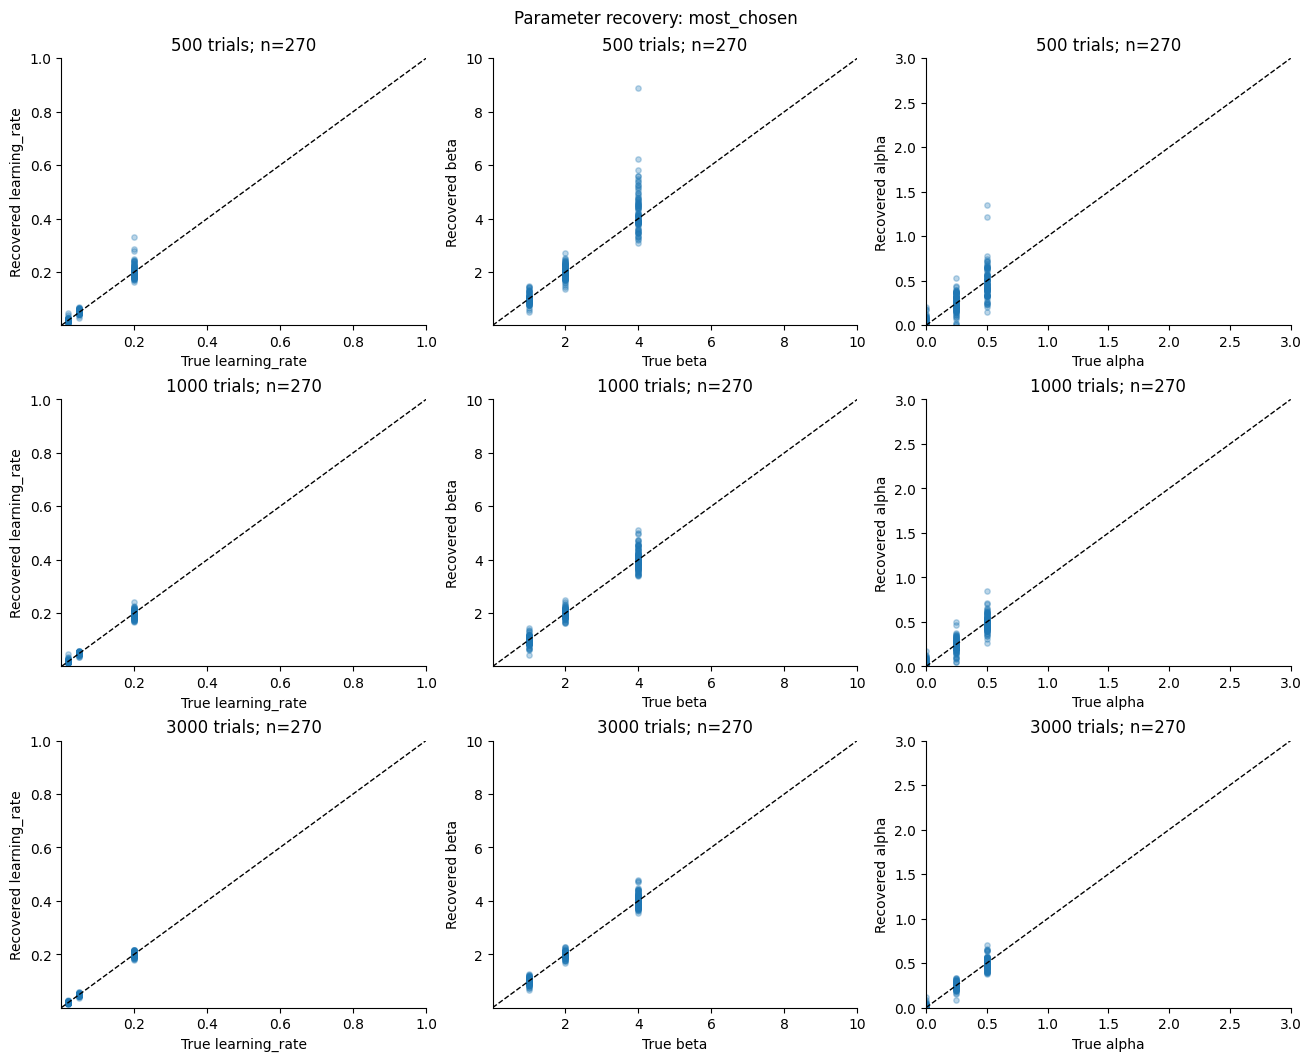

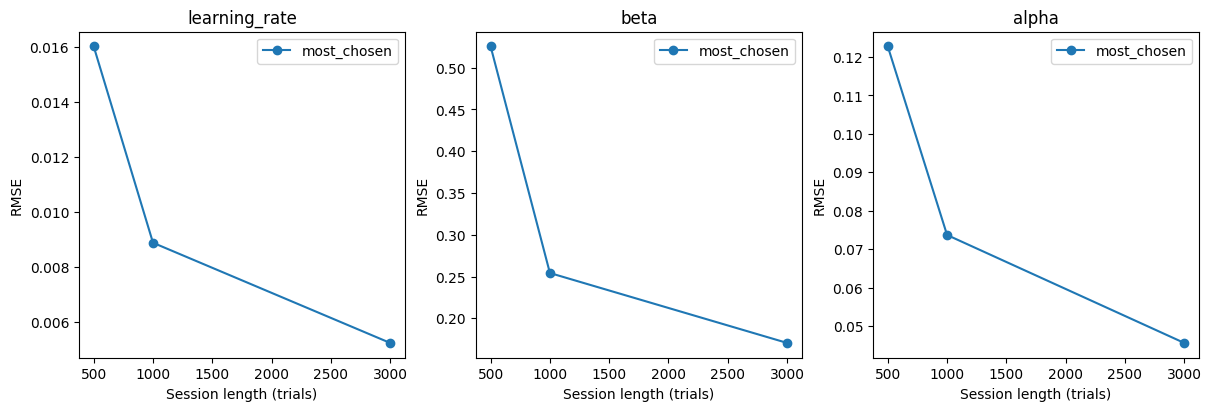

In [29]:
# True versus recovered values, separated by swap mode and session length.
successful = recovery_results.loc[recovery_results.success].copy()
for mode in recovery_config["swap_modes"]:
    lengths = recovery_config["trial_lengths"]
    fig, axes = plt.subplots(len(lengths), 3, figsize=(13, 3.5 * len(lengths)),
                             squeeze=False, layout="constrained")
    for row_index, length in enumerate(lengths):
        subset = successful.loc[(successful.swap_mode == mode)
                                & (successful.num_trials == length)]
        for col_index, (name, limits) in enumerate(zip(PARAMETER_NAMES, PARAMETER_BOUNDS)):
            ax = axes[row_index, col_index]
            ax.scatter(subset[f"true_{name}"], subset[f"recovered_{name}"],
                       s=15, alpha=0.3)
            ax.plot(limits, limits, "--", color="black", linewidth=1)
            ax.set(xlim=limits, ylim=limits, xlabel=f"True {name}",
                   ylabel=f"Recovered {name}", title=f"{length} trials; n={len(subset)}")
            ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(f"Parameter recovery: {mode}")
    fig.savefig(recovery_output_dir / f"recovery_{mode}.png", dpi=160)
    plt.show()

# How recovery error changes with available data.
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, name in zip(axes, PARAMETER_NAMES):
    for mode in recovery_config["swap_modes"]:
        subset = recovery_summary.loc[(recovery_summary.parameter == name)
                                      & (recovery_summary.swap_mode == mode)].sort_values("num_trials")
        ax.plot(subset.num_trials, subset.rmse, "o-", label=mode)
    ax.set(xlabel="Session length (trials)", ylabel="RMSE", title=name)
    ax.legend()
fig.savefig(recovery_output_dir / "rmse_by_session_length.png", dpi=160)
plt.show()

### Parameter trade-offs
The heatmaps correlate **estimation errors**, not raw estimates, within each task/length condition. Off-diagonal relationships can reveal compensating parameter estimates, but also reflect the mixture of generating settings; inspect `recovery_by_setting` before interpreting them. The final table compares recovery of the effective stickiness coefficient `beta * alpha` with its true value. These diagnostics do not provide confidence intervals or establish unique parameter identification.

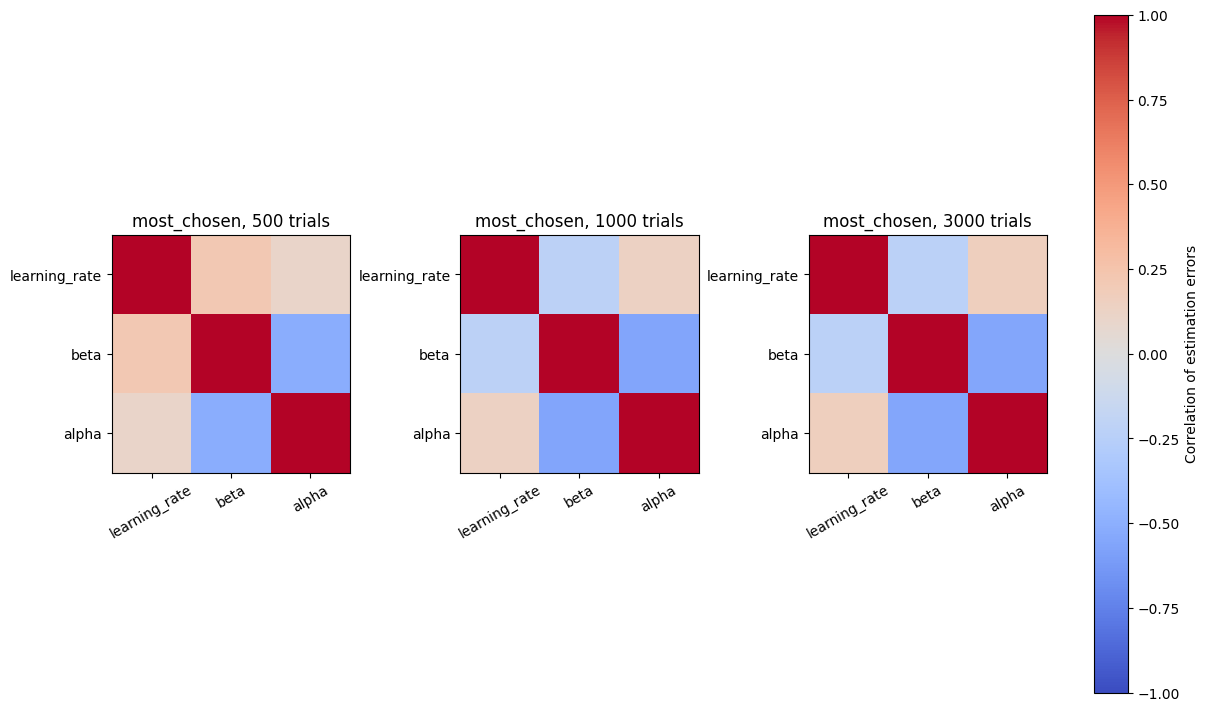

,swap_mode,num_trials,n_success,beta_alpha_bias,beta_alpha_rmse
0,most_chosen,500,270,0.005162,0.194088
1,most_chosen,1000,270,0.005129,0.123488
2,most_chosen,3000,270,0.006621,0.067850


In [30]:
tradeoff_rows = []
fig, axes = plt.subplots(len(recovery_config["swap_modes"]),
                         len(recovery_config["trial_lengths"]),
                         figsize=(12, 7), squeeze=False, layout="constrained")
for row_index, mode in enumerate(recovery_config["swap_modes"]):
    for col_index, length in enumerate(recovery_config["trial_lengths"]):
        subset = successful.loc[(successful.swap_mode == mode)
                                & (successful.num_trials == length)]
        errors = pd.DataFrame({name: subset[f"recovered_{name}"] - subset[f"true_{name}"]
                               for name in PARAMETER_NAMES})
        ax = axes[row_index, col_index]
        im = ax.imshow(errors.corr(), vmin=-1, vmax=1, cmap="coolwarm")
        ax.set_xticks(range(3), PARAMETER_NAMES, rotation=30)
        ax.set_yticks(range(3), PARAMETER_NAMES)
        ax.set_title(f"{mode}, {length} trials")
        product_error = (subset.recovered_beta * subset.recovered_alpha
                         - subset.true_beta * subset.true_alpha)
        tradeoff_rows.append({"swap_mode": mode, "num_trials": length,
                             "n_success": len(subset),
                             "beta_alpha_bias": product_error.mean(),
                             "beta_alpha_rmse": np.sqrt((product_error ** 2).mean())})
fig.colorbar(im, ax=axes.ravel().tolist(), label="Correlation of estimation errors")
fig.savefig(recovery_output_dir / "parameter_error_correlations.png", dpi=160)
plt.show()
tradeoff_summary = pd.DataFrame(tradeoff_rows)
tradeoff_summary.to_csv(recovery_output_dir / "effective_stickiness_summary.csv", index=False)
display(tradeoff_summary)

## Cohort 1: fit problems 5–11 with leave-one-problem-out validation
This section can run independently of the synthetic recovery sweep. MY_71_N has six fits over problems 5–10 (train on five, test on one). Each other mouse has seven fits over problems 5–11 (train on six, test on one). Problems use the **existing analysis pipeline's ordinal numbering**, assigned from the full eligible session history before selecting 5–11. Raw `num_problem` values are not used.

The model uses learning rate, beta, and nonnegative stickiness alpha, with the same softmax parameterisation as the simulation. Rewards are **delivered reward pulses** (`reward_pulses`), including zeros. Arm identities are physical tower labels, never reward ranks. Q-values and previous-choice memory reset at each extracted session (including configuration-split sessions); this is an explicit modelling assumption. Training loss is trial-weighted across training sessions for that mouse.

Held-out choices are predicted before each reward update. Past held-out observations update Q-values during sequential scoring, but fitted parameters remain fixed. No held-out outcomes are used to optimise parameters or select optimisation starts. The folds overlap in training data, so they are not independent subjects. This evaluates generalisation across problems, not strictly forward-in-time forecasting.

Sessions with missing/invalid choice or reward histories are excluded as a whole and audited. Mice need usable data in every problem requested for that mouse; MY_71_N has an explicit exception because problem 11 is unavailable. Fits at parameter bounds are flagged. Do not tune model settings against these held-out scores and then treat the same scores as untouched test performance.

In [31]:
# Independent setup: no need to run the synthetic recovery experiment first.
import importlib
import json
import sys
from pathlib import Path
from unittest.mock import patch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cohort_repo_root = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "src/behavior_import").is_dir()), None
)
if cohort_repo_root is None:
    raise RuntimeError("Run this notebook from within the repository.")
if str(cohort_repo_root) not in sys.path:
    sys.path.insert(0, str(cohort_repo_root))

from src.agents.cohort_fitting import (
    prepare_cohort_sequences, run_problem_cross_validation,
)
from src.behavior_import.extract_trials import extract_trials_grouped_by_problem
cohort_import = importlib.import_module("src.behavior_import.import_data")

# Match the existing cohort-1 analysis notebook. Mount the drive or edit this path.
cohort_data_root = Path("/Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01")
cohort_problem_numbers = list(range(5, 12))
cohort_excluded_task_parts = ("mag", "pretraining")
cohort_fit_bounds = [(0.001, 1.0), (0.01, 10.0), (0.0, 3.0)]
cohort_fit_starts = 10
cohort_fit_seed = 42
cohort_output_root = cohort_repo_root / "results/cohort_01_parameter_fitting"
# Explicit exception: six folds for this mouse; seven for all others.
cohort_problem_overrides = {"MY_71_N": list(range(5, 11))}


In [32]:
# Load all eligible sessions first: filtering to later sessions beforehand
# would change the pipeline's ordinal problem numbering.
if not cohort_data_root.is_dir():
    raise FileNotFoundError(
        f"Cohort 1 data not found: {cohort_data_root}. "
        "Mount the data drive or set cohort_data_root to the full cohort directory."
    )
cohort_files = cohort_import.collect_tsv_files(cohort_data_root.resolve())
cohort_eligible_files = []
cohort_file_rows = []
for path, frame in cohort_files:
    task_rows = frame.loc[
        frame["type"].eq("info") & frame["subtype"].eq("task_name"), "content"
    ]
    task_name = str(task_rows.iloc[0]) if len(task_rows) else None
    keep = task_name is not None and not any(
        part in task_name.casefold() for part in cohort_excluded_task_parts
    )
    cohort_file_rows.append({"path": str(path), "task_name": task_name, "included": keep})
    if keep:
        cohort_eligible_files.append((path, frame))
cohort_file_audit = pd.DataFrame(cohort_file_rows, columns=["path", "task_name", "included"])
display(cohort_file_audit.groupby(["task_name", "included"], dropna=False).size().rename("files"))
if not cohort_eligible_files:
    raise ValueError("No eligible task files remain; check the root and the task-name audit.")
with patch.object(cohort_import, "collect_tsv_files", return_value=cohort_eligible_files):
    cohort_raw = cohort_import.import_data(cohort_data_root)
cohort_all_problems = extract_trials_grouped_by_problem(cohort_raw, merge_recurring_problems=False)
print("Available pipeline problem numbers:", sorted(cohort_all_problems))
missing_problems = sorted(set(cohort_problem_numbers) - set(cohort_all_problems))
if missing_problems:
    raise ValueError(
        f"Missing requested pipeline problems: {missing_problems}. "
        "Check the complete cohort data and task filtering; problem numbers will not be relabelled."
    )
cohort_sequences, cohort_session_audit = prepare_cohort_sequences(
    cohort_all_problems, cohort_problem_numbers
)
display(cohort_session_audit.groupby(["mouse", "problem", "included"]).agg(
    sessions=("session", "size"), trials=("n_trials", "sum")
))
display(cohort_session_audit.loc[~cohort_session_audit.included])

[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-01_id-MY_71_N/ses-08_date-20260204/behav/._MY_71_N-2026-02-04-153602.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-05_id-MY_72_L/ses-155_date-20260613/behav/._MY_72_L-2026-06-13-201430.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-02_id-MY_71_L/ses-54_date-20260305/behav/._MY_71_L-2026-03-05-150416.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/3x3_field_magnitude_bandit/rawdata/cohort-01/sub-04_id-MY_72_N/ses-40_date-20260225/behav/._MY_72_N-2026-02-25-143929.tsv: 'utf-8' codec can't decode byte 0xb0 in position 37: invalid start byte.
[WARN] Failed to read /Volumes/behrens/meg/

task_name                                              included
Meg\3x3_field_blocked_reward_bandit_with_cue           True        316
Meg\3x3_field_drifting_value_bandit                    True        467
Meg\3x3_field_drifting_value_bandit_for_recording_71R  True        126
Meg\3x3_field_drifting_value_bandit_for_recording_72L  True         83
Name: files, dtype: int64

/Users/megyoung/magnitude-bandit-analysis/src/behavior_import/import_data.py:226: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col] = norm[col]
/Users/megyoung/magnitude-bandit-analysis/src/behavior_import/import_data.py:226: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[col] = norm[col]
/Users/megyoung/magnitude-bandit-analysis/src/behavior_import/import_data.py:226: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider 

[INFO] Processed 6 subjects(s), 882 session(s).
[INFO] Split MY_71_R ses-213_date-20260725 into 2 recording segments because the tower configuration changed.
[WARNING] No trial information found for subject MY_72_R, session ses-1_date-20260201
[WARNING] No trial information found for subject MY_72_R, session ses-2_date-20260201
[WARNING] No trial information found for subject MY_72_R, session ses-3_date-20260202
[WARNING] No trial information found for subject MY_72_R, session ses-4_date-20260202
[WARNING] No trial information found for subject MY_72_R, session ses-5_date-20260203
[INFO] Merging multiple files for subject MY_72_R, session ses-6_date-20260203
[INFO] Merging multiple files for subject MY_72_R, session ses-42_date-20260226
[INFO] Merging multiple files for subject MY_72_R, session ses-57_date-20260309
[WARNING] No trial information found for subject MY_71_N, session ses-1_date-20260201
[WARNING] No trial information found for subject MY_71_N, session ses-2_date-20260201
[

sessions  trials
mouse   problem included                  
MY_71_L 5       True             8     462
        6       True             7     436
        7       True             9     503
        8       True             8     442
        9       True             7     326
        10      True             8     519
        11      True             6     413
MY_71_N 5       True             8     518
        6       True             8     500
        7       True             7     382
        8       True             7     357
        9       True             6     387
        10      True             5     315
MY_71_R 5       True             7     475
        6       True             7     456
        7       True             8     480
        8       True             7     427
        9       True             6     318
        10      True             8     537
        11      True             6     421
MY_72_L 5       True             8     429
        6       True             6     458
        7       True            10     551
        8       True             8     414
        9       True             9     367
        10      True             6     419
        11      True             8     512
MY_72_N 5       True             9     381
        6       True             6     416
        7       True             7     476
        8       True             8     441
        9       True             8     361
        10      True             7     445
        11      True             8     463
MY_72_R 5       True            10     562
        6       True             8     523
        7       True             8     537
        8       True             8     484
        9       True             7     393
        10      True             8     658
        11      True             8     615

,mouse,problem,session,n_trials,included,reason,reward_min,reward_max,towers


In [33]:
# Run/resume all seven folds for each eligible mouse. Each fold is saved.
cohort_cv_results, cohort_test_sessions, cohort_eligibility, cohort_fit_dir = (
    run_problem_cross_validation(
        cohort_sequences, cohort_output_root,
        problem_numbers=cohort_problem_numbers, bounds=cohort_fit_bounds,
        n_starts=cohort_fit_starts, seed=cohort_fit_seed,
        source_metadata={
            "root": str(cohort_data_root.resolve()),
            "excluded_task_name_parts": list(cohort_excluded_task_parts),
            "problem_numbering": "existing_pipeline_contiguous_ordinal",
            "merge_recurring_problems": False,
        },
    )
)
cohort_file_audit.to_csv(cohort_fit_dir / "input_files.csv", index=False)
cohort_session_audit.to_csv(cohort_fit_dir / "session_audit.csv", index=False)
# Include mice whose every requested session was rejected by data validation.
audit_mice = set(cohort_session_audit.mouse)
missing_mice = audit_mice - set(cohort_eligibility.mouse)
if missing_mice:
    cohort_eligibility = pd.concat([
        cohort_eligibility,
        pd.DataFrame([{"mouse": mouse, "eligible": False,
                       "missing_problems": ",".join(map(str, cohort_problem_numbers))}
                      for mouse in sorted(missing_mice)]),
    ], ignore_index=True)
cohort_eligibility.to_csv(cohort_fit_dir / "mouse_eligibility.csv", index=False)
display(cohort_eligibility)
if cohort_cv_results.empty:
    raise ValueError(f"No mice have usable trials in all seven problems. See audits in {cohort_fit_dir}.")
display(cohort_cv_results)
print(f"Saved fits, optimisation starts, and held-out trial predictions to {cohort_fit_dir}")

# Preserve the original seven-fold run and fit the explicit six-fold exception.
cohort_seven_fold_dir = cohort_fit_dir
cohort_run_dirs = {"seven_fold": str(cohort_seven_fold_dir)}
for exception_mouse, exception_problems in cohort_problem_overrides.items():
    exception_sequences = [s for s in cohort_sequences if s["mouse"] == exception_mouse]
    extra_results, extra_sessions, extra_eligibility, extra_dir = run_problem_cross_validation(
        exception_sequences, cohort_output_root,
        problem_numbers=exception_problems, bounds=cohort_fit_bounds,
        n_starts=cohort_fit_starts, seed=cohort_fit_seed,
        source_metadata={
            "root": str(cohort_data_root.resolve()),
            "excluded_task_name_parts": list(cohort_excluded_task_parts),
            "problem_numbering": "existing_pipeline_contiguous_ordinal",
            "merge_recurring_problems": False,
            "mouse": exception_mouse,
        },
    )
    cohort_run_dirs[exception_mouse] = str(extra_dir)
    cohort_cv_results = pd.concat([
        cohort_cv_results.loc[cohort_cv_results.mouse.ne(exception_mouse)], extra_results
    ], ignore_index=True)
    cohort_test_sessions = pd.concat([
        cohort_test_sessions.loc[cohort_test_sessions.mouse.ne(exception_mouse)], extra_sessions
    ], ignore_index=True)
    cohort_eligibility = pd.concat([
        cohort_eligibility.loc[cohort_eligibility.mouse.ne(exception_mouse)], extra_eligibility
    ], ignore_index=True)
cohort_fit_dir = cohort_output_root / "combined_with_MY_71_N_six_folds"
cohort_fit_dir.mkdir(parents=True, exist_ok=True)
cohort_eligibility["requested_problems"] = cohort_eligibility.mouse.map(
    lambda m: ",".join(map(str, cohort_problem_overrides.get(m, cohort_problem_numbers))))
cohort_eligibility["expected_folds"] = cohort_eligibility.mouse.map(
    lambda m: len(cohort_problem_overrides.get(m, cohort_problem_numbers)))
cohort_cv_results = cohort_cv_results.sort_values(["mouse", "held_out_problem"])
cohort_cv_results.to_csv(cohort_fit_dir / "fold_results.csv", index=False)
cohort_test_sessions.to_csv(cohort_fit_dir / "held_out_sessions.csv", index=False)
cohort_eligibility.to_csv(cohort_fit_dir / "mouse_eligibility.csv", index=False)
cohort_file_audit.to_csv(cohort_fit_dir / "input_files.csv", index=False)
cohort_session_audit.to_csv(cohort_fit_dir / "session_audit.csv", index=False)
(cohort_fit_dir / "source_runs.json").write_text(json.dumps(cohort_run_dirs, indent=2))
display(cohort_eligibility)
print(f"Combined results saved to {cohort_fit_dir}; detailed fits/predictions remain in source runs.")


,mouse,eligible,missing_problems
0,MY_71_L,True,
1,MY_71_N,False,11
2,MY_71_R,True,
3,MY_72_L,True,
4,MY_72_N,True,
5,MY_72_R,True,


,mouse,held_out_problem,training_problems,n_train_trials,n_test_trials,n_train_sessions,n_test_sessions,success,converged_starts,train_cross_entropy,test_cross_entropy,uniform_cross_entropy,improvement_over_uniform,learning_rate,at_bound_learning_rate,beta,at_bound_beta,alpha,at_bound_alpha
0,MY_71_L,5,"6,7,8,9,10,11",2639,462,45,8,True,10,0.577626,0.891819,1.098612,0.206794,0.319790,False,0.699555,False,1.938345,False
1,MY_71_L,6,"5,7,8,9,10,11",2665,436,46,7,True,10,0.630765,0.576193,1.098612,0.522419,0.316243,False,0.648879,False,1.940600,False
2,MY_71_L,7,"5,6,8,9,10,11",2598,503,44,9,True,10,0.646289,0.504980,1.098612,0.593632,0.312669,False,0.622420,False,2.052280,False
3,MY_71_L,8,"5,6,7,9,10,11",2659,442,45,8,True,10,0.645787,0.489836,1.098612,0.608776,0.303027,False,0.662273,False,1.776178,False
4,MY_71_L,9,"5,6,7,8,10,11",2775,326,46,7,True,10,0.613872,0.702435,1.098612,0.396177,0.298309,False,0.700117,False,1.745152,False
5,MY_71_L,10,"5,6,7,8,9,11",2582,519,45,8,True,10,0.604135,0.718166,1.098612,0.380446,0.320834,False,0.676251,False,1.893414,False
6,MY_71_L,11,"5,6,7,8,9,10",2688,413,47,6,True,10,0.639400,0.519987,1.098612,0.578626,0.280115,False,0.682438,False,1.765150,False
7,MY_71_R,5,"6,7,8,9,10,11",2639,475,42,7,True,10,0.773217,0.845982,1.098612,0.252630,0.262293,False,0.581665,False,1.613500,False
8,MY_71_R,6,"5,7,8,9,10,11",2658,456,42,7,True,10,0.778542,0.814809,1.098612,0.283803,0.229239,False,0.605225,False,1.513477,False
9,MY_71_R,7,"5,6,8,9,10,11",2634,480,41,8,True,10,0.799440,0.698502,1.098612,0.400110,0.227602,False,0.621536,False,1.346912,False


Saved fits, optimisation starts, and held-out trial predictions to /Users/megyoung/magnitude-bandit-analysis/results/cohort_01_parameter_fitting/6e4d66a81750


,mouse,eligible,missing_problems,requested_problems,expected_folds
0,MY_71_L,True,,"5,6,7,8,9,10,11",7
1,MY_71_R,True,,"5,6,7,8,9,10,11",7
2,MY_72_L,True,,"5,6,7,8,9,10,11",7
3,MY_72_N,True,,"5,6,7,8,9,10,11",7
4,MY_72_R,True,,"5,6,7,8,9,10,11",7
5,MY_71_N,True,,"5,6,7,8,9,10",6


Combined results saved to /Users/megyoung/magnitude-bandit-analysis/results/cohort_01_parameter_fitting/combined_with_MY_71_N_six_folds; detailed fits/predictions remain in source runs.


### Held-out performance and parameter stability
Cross entropy is measured in nats per choice; lower is better. Positive improvement over `log(3)` means better prediction than uniform choice. This is a minimal baseline, not evidence that Q-learning outperforms other behavioural models.

Per-mouse aggregate scores are reported only when all requested folds succeed (six for MY_71_N, seven for other mice). Each held-out trial then appears exactly once in the aggregate; trial-weighting differs from giving each problem equal weight. Across-mouse summaries give each mouse equal weight. Parameter plots show the six or seven training-fold estimates per mouse, not seven independent estimates or confidence intervals. These are cross-validation fits, not an additional all-problems refit.

,n_folds,total_held_out_nll,total_held_out_trials,mean_problem_cross_entropy,trial_weighted_cross_entropy,improvement_over_uniform
mouse,,,,,,
MY_71_L,7,1950.229598,3101,0.629059,0.628903,0.469709
MY_71_N,6,1924.221680,2459,0.780518,0.782522,0.316090
MY_71_R,7,2458.168844,3114,0.788641,0.789393,0.309220
MY_72_L,7,2228.930630,3150,0.709864,0.707597,0.391015
MY_72_N,7,2350.827274,2983,0.794043,0.788075,0.310537
MY_72_R,7,2970.389341,3772,0.786940,0.787484,0.311128


Mice with all requested folds complete: 6
Mean across mice (equal mouse weight): 0.7473289947382827
Failed folds: 0


,mouse,held_out_problem,learning_rate,beta,alpha,at_bound_learning_rate,at_bound_beta,at_bound_alpha
0,MY_71_L,5,0.319790,0.699555,1.938345,False,False,False
1,MY_71_L,6,0.316243,0.648879,1.940600,False,False,False
2,MY_71_L,7,0.312669,0.622420,2.052280,False,False,False
3,MY_71_L,8,0.303027,0.662273,1.776178,False,False,False
4,MY_71_L,9,0.298309,0.700117,1.745152,False,False,False
5,MY_71_L,10,0.320834,0.676251,1.893414,False,False,False
6,MY_71_L,11,0.280115,0.682438,1.765150,False,False,False
35,MY_71_N,5,0.193335,0.452428,3.000000,False,False,True
36,MY_71_N,6,0.204064,0.515776,2.172442,False,False,False
37,MY_71_N,7,0.154136,0.522205,2.340277,False,False,False


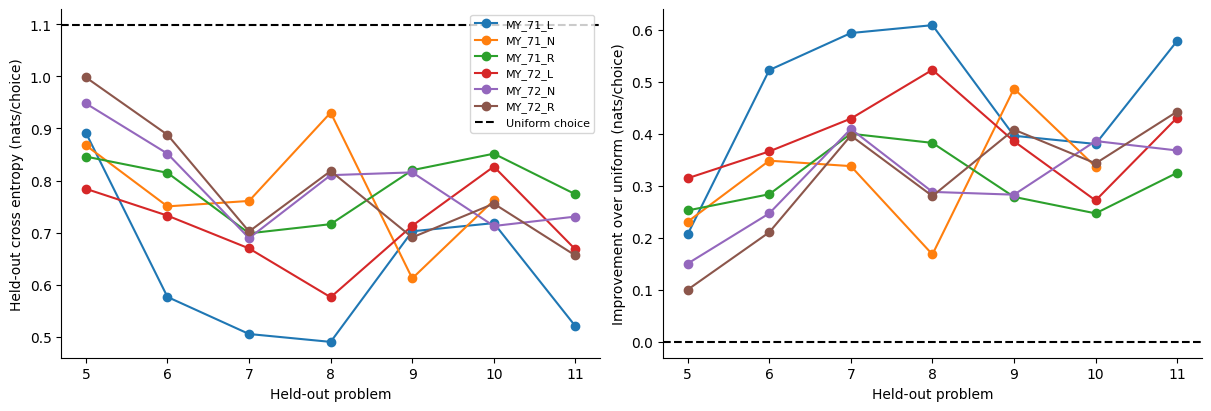

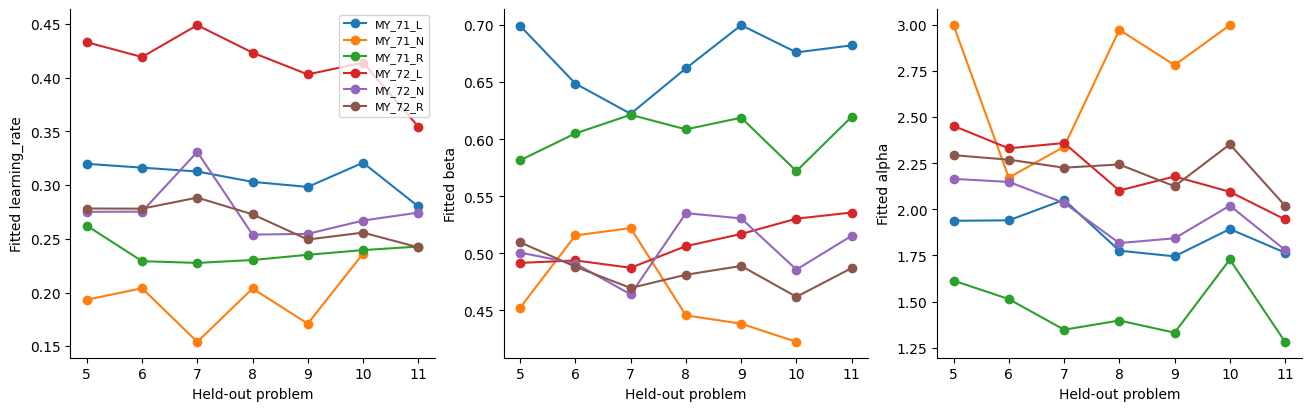

In [34]:
cohort_cv_success = cohort_cv_results.loc[cohort_cv_results.success].copy()
cohort_cv_success["held_out_nll"] = (
    cohort_cv_success.test_cross_entropy * cohort_cv_success.n_test_trials
)
complete_mice = cohort_cv_success.groupby("mouse").held_out_problem.nunique()
expected_folds = pd.Series({m: len(cohort_problem_overrides.get(m, cohort_problem_numbers))
                            for m in complete_mice.index})
complete_mice = complete_mice.index[complete_mice.eq(expected_folds)]
cohort_complete_folds = cohort_cv_success.loc[cohort_cv_success.mouse.isin(complete_mice)]
cohort_mouse_scores = cohort_complete_folds.groupby("mouse").agg(
    n_folds=("held_out_problem", "nunique"),
    total_held_out_nll=("held_out_nll", "sum"),
    total_held_out_trials=("n_test_trials", "sum"),
    mean_problem_cross_entropy=("test_cross_entropy", "mean"),
)
cohort_mouse_scores["trial_weighted_cross_entropy"] = (
    cohort_mouse_scores.total_held_out_nll / cohort_mouse_scores.total_held_out_trials
)
cohort_mouse_scores["improvement_over_uniform"] = (
    np.log(3) - cohort_mouse_scores.trial_weighted_cross_entropy
)
cohort_mouse_scores.to_csv(cohort_fit_dir / "mouse_cv_scores.csv")
display(cohort_mouse_scores)
print(f"Mice with all requested folds complete: {len(complete_mice)}")
print("Mean across mice (equal mouse weight):",
      cohort_mouse_scores.trial_weighted_cross_entropy.mean())
print("Failed folds:", int((~cohort_cv_results.success).sum()))
display(cohort_cv_success[["mouse", "held_out_problem", "learning_rate", "beta", "alpha",
                          "at_bound_learning_rate", "at_bound_beta", "at_bound_alpha"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for mouse, group in cohort_cv_success.groupby("mouse"):
    group = group.sort_values("held_out_problem")
    axes[0].plot(group.held_out_problem, group.test_cross_entropy, "o-", label=mouse)
    axes[1].plot(group.held_out_problem, group.improvement_over_uniform, "o-", label=mouse)
axes[0].axhline(np.log(3), color="black", linestyle="--", label="Uniform choice")
axes[1].axhline(0, color="black", linestyle="--")
axes[0].set_ylabel("Held-out cross entropy (nats/choice)")
axes[1].set_ylabel("Improvement over uniform (nats/choice)")
for ax in axes:
    ax.set_xlabel("Held-out problem")
    ax.set_xticks(cohort_problem_numbers)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(fontsize=8)
fig.savefig(cohort_fit_dir / "held_out_performance.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, parameter in zip(axes, ["learning_rate", "beta", "alpha"]):
    for mouse, group in cohort_cv_success.groupby("mouse"):
        group = group.sort_values("held_out_problem")
        ax.plot(group.held_out_problem, group[parameter], "o-", label=mouse)
    ax.set(xlabel="Held-out problem", ylabel=f"Fitted {parameter}")
    ax.set_xticks(cohort_problem_numbers)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(fontsize=8)
fig.savefig(cohort_fit_dir / "parameter_stability_across_folds.png", dpi=160)
plt.show()

### Parameter values across mice
Each coloured dot is one training-fold estimate; black bars show their mean. MY_71_N uses six folds over problems 5–10; the other mice use seven folds over problems 5–11. Folds overlap in training data, so their spread is not a confidence interval. These are not all-problems refits.

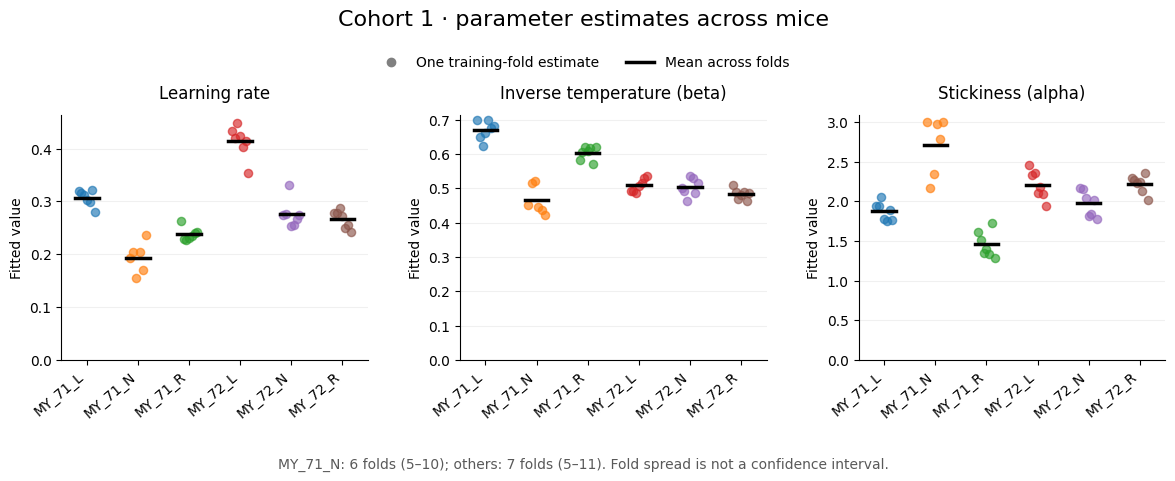

In [35]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

plot_repo_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                      if (p / "src/agents/cohort_fitting.py").exists())
parameter_plot_dir = Path(globals().get(
    "cohort_fit_dir",
    plot_repo_root / "results/cohort_01_parameter_fitting/combined_with_MY_71_N_six_folds",
))
parameter_folds = pd.read_csv(parameter_plot_dir / "fold_results.csv")
parameter_folds = parameter_folds.loc[parameter_folds.success].copy()
parameter_mice = sorted(parameter_folds.mouse.unique())
parameter_names = ["learning_rate", "beta", "alpha"]
parameter_titles = ["Learning rate", "Inverse temperature (beta)", "Stickiness (alpha)"]
parameter_means = parameter_folds.groupby("mouse")[parameter_names].mean().reindex(parameter_mice)
parameter_means.to_csv(parameter_plot_dir / "parameter_means_across_folds.csv")

fig, axes = plt.subplots(1, 3, figsize=(12, 4.8))
colors = plt.get_cmap("tab10").colors
for ax, name, title in zip(axes, parameter_names, parameter_titles):
    for i, mouse_name in enumerate(parameter_mice):
        values = parameter_folds.loc[parameter_folds.mouse.eq(mouse_name)].sort_values("held_out_problem")[name]
        offsets = np.linspace(-0.16, 0.16, len(values))
        ax.scatter(i + offsets, values, s=35, color=colors[i], alpha=0.65, zorder=3)
        ax.plot([i - 0.23, i + 0.23], [values.mean()] * 2,
                color="black", linewidth=2.5, zorder=4)
    ax.set_title(title, fontsize=12, pad=12)
    ax.set_xticks(range(len(parameter_mice)), parameter_mice, rotation=40, ha="right")
    ax.set_ylabel("Fitted value")
    ax.set_xlim(-0.5, len(parameter_mice) - 0.5)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.18)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Cohort 1 · parameter estimates across mice", fontsize=16, y=0.98)
fig.legend(handles=[
    Line2D([], [], color="0.5", marker="o", linestyle="none", label="One training-fold estimate"),
    Line2D([], [], color="black", linewidth=2.5, label="Mean across folds"),
], loc="upper center", bbox_to_anchor=(0.5, 0.91), ncol=2, frameon=False)
fig.text(0.5, 0.025, "MY_71_N: 6 folds (5–10); others: 7 folds (5–11). Fold spread is not a confidence interval.",
         ha="center", fontsize=10, color="0.35")
fig.subplots_adjust(top=0.76, bottom=0.25, left=0.065, right=0.985, wspace=0.30)
for extension in ("png", "pdf"):
    fig.savefig(parameter_plot_dir / f"parameters_across_mice.{extension}", dpi=180, bbox_inches="tight")
plt.show()


## Best RL: six-parameter written-paper equations

Published source: [Eckstein et al., Nature Human Behaviour (2026)](https://doi.org/10.1038/s41562-025-02324-0), supplied as `s41562-025-02324-0-2.pdf`. Code pinned to [`baf38da49fd1c1537affbc3745e961bbf0ae547d`](https://github.com/google-deepmind/hybrid_rnns_reward_learning/tree/baf38da49fd1c1537affbc3745e961bbf0ae547d). The article and code differ in several details; the distinctions below are deliberate. Restart the kernel before using the updated modules. Previous source/notebook versions are archived under `results/model_implementation_archive/pre_release_alignment_*`; existing result directories are preserved.

This section follows the published paper's Eq. 2, including a chosen-value bias. It is deliberately labelled separately from the released CogMod, where that bias is absent.

Before choice: `p = softmax(beta * (Q + kappa * previous_choice_one_hot))`.
After reward: `Q[chosen] += learning_rate*(reward-Q[chosen]) + bias`, followed by `Q = (1-forgetting)*Q + forgetting*q_init` for **all** actions. Reset Q to q_init and previous-choice memory to none per session. The paper's alpha corresponds to `learning_rate`; kappa is signed perseverance.

The SciPy fitter uses direct bounds: rates in (0,1), bias/kappa in (-1,1), beta positive, q_init unrestricted (epsilon at open endpoints). The population fitter below uses sigmoid rates, tanh bias/kappa, **ReLU** beta, and free q_init, aligning common transforms with the released CogMod. ReLU permits beta=0. Reward units remain delivered pulses and affect value-scale parameters and constraints.

**Structural identifiability:** set x=Q-q_init. Choice likelihood depends on bias and initial Q through `bias - learning_rate*q_init`; shifting q_init by δ and bias by learning_rate×δ leaves predictions unchanged within the parameter bounds. Retaining six named parameters does not establish six independently identifiable behavioral effects. This exact two-parameter confound does not apply to released CogMod because bias is fixed at zero, though other trade-offs may remain.

The synthetic example and per-mouse fits here use unregularized multi-start L-BFGS-B on full observed histories. They implement the architecture but not the population training protocol. Neither lower training loss nor successful optimizer convergence establishes parameter recovery or model superiority.


In [36]:
# Independent imports; this section can run without the earlier recovery sweep.
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
best_repo_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                      if (p / "src/agents/best_rl.py").exists())
if str(best_repo_root) not in sys.path:
    sys.path.insert(0, str(best_repo_root))
from src.agents.best_rl import (
    BestRLMouse, PARAMETER_NAMES as BEST_RL_PARAMETER_NAMES,
    DEFAULT_BOUNDS as BEST_RL_BOUNDS, fit_mouse_sessions as fit_best_rl,
    multi_session_loss as best_rl_loss,
)
from src.tasks.drifting_bandit import DriftingBanditTask
from src.agents.cohort_fitting import run_problem_cross_validation


### Synthetic Best RL recovery example
A single fresh synthetic session illustrates simulation and fitting. This is a smoke/recovery example, not a factorial identification study. It leaves the original session and recovery results intact. Run this cell explicitly; it may take time.


In [37]:
best_generating_params = dict(learning_rate=0.25, beta=2.0, kappa=0.2,
                              bias=0.05, forgetting=0.05, q_init=0.5)
# Preserve global RNG state used by other notebook simulations.
import random
best_numpy_state, best_python_state = np.random.get_state(), random.getstate()
try:
    np.random.seed(42)
    random.seed(42)
    best_task = DriftingBanditTask([0, 1, 4], drift_rate=0.1, swap_mode="most_chosen")
    best_mouse = BestRLMouse(3, **best_generating_params)
    best_actions, best_rewards, best_q_values = best_task.simulate(best_mouse, 1000)
finally:
    np.random.set_state(best_numpy_state)
    random.setstate(best_python_state)
best_synthetic_sequence = dict(towers=[0, 1, 2], actions=np.asarray(best_actions),
                               rewards=np.asarray(best_rewards, dtype=float))
best_synthetic_fit, best_synthetic_starts = fit_best_rl(
    [best_synthetic_sequence], n_starts=10, seed=42)
if best_synthetic_fit is None:
    raise RuntimeError("All Best RL starts failed; inspect best_synthetic_starts.")
best_recovery_table = pd.DataFrame({
    "true": best_generating_params,
    "recovered": dict(zip(BEST_RL_PARAMETER_NAMES, best_synthetic_fit["parameters"])),
})
best_recovery_table["error"] = best_recovery_table.recovered-best_recovery_table.true
display(best_recovery_table)
print("True loss:", best_rl_loss(list(best_generating_params.values()), [best_synthetic_sequence])[0])
print("Fitted loss:", best_synthetic_fit["loss"])
display(pd.DataFrame(best_synthetic_starts))

print("Identifiable bias combination (true / fitted):",
      best_generating_params["bias"]-best_generating_params["learning_rate"]*best_generating_params["q_init"],
      best_synthetic_fit["parameters"][3]-best_synthetic_fit["parameters"][0]*best_synthetic_fit["parameters"][5])


,true,recovered,error
learning_rate,0.25,0.231176,-0.018824
beta,2.00,2.330776,0.330776
kappa,0.20,0.182364,-0.017636
bias,0.05,0.088658,0.038658
forgetting,0.05,0.094457,0.044457
q_init,0.50,0.870386,0.370386


True loss: 0.40760724621157035
Fitted loss: 0.40450999895855433


,start,success,loss,parameters,message
0,0,True,0.40451,"[0.23117671724585936, 2.330750077178544, 0.182...",CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
1,1,True,0.40451,"[0.23119688298934254, 2.330577077009857, 0.182...",CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
2,2,True,0.40451,"[0.2311674377735161, 2.3309291214527117, 0.182...",CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
3,3,True,0.40451,"[0.2311791712968458, 2.330740838138921, 0.1823...",CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
4,4,True,0.40451,"[0.23117871384335825, 2.3307358455834244, 0.18...",CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
5,5,True,0.40451,"[0.23117642533384927, 2.330737153080016, 0.182...",CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
6,6,True,0.40451,"[0.23117555082085225, 2.3307763281439278, 0.18...",CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
7,7,True,0.40451,"[0.2311784226595353, 2.3307530360533715, 0.182...",CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
8,8,True,0.40451,"[0.23117793531152375, 2.3307813865018883, 0.18...",CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
9,9,True,0.40451,"[0.23119469471480344, 2.330529168683839, 0.182...",CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...


Identifiable bias combination (true / fitted): -0.075 -0.11255402326623538


### Best RL cohort fits and matched held-out comparison
First run the existing cohort setup and data-loading cells (beginning `# Independent setup` and `# Load all eligible sessions first`). This uses the same sessions, pulses, tower identities, fold definitions and MY_71_N exception as the existing model. Outputs are stored separately and resume by manifest, including Best RL source and update order. No old three-parameter fits are overwritten. Fit starts are selected on training loss only.


In [38]:
if "cohort_sequences" not in globals():
    raise RuntimeError("Run the cohort setup and data-loading cells first.")
best_fold_frames, best_session_frames, best_eligibility_frames = [], [], []
best_run_dirs = {}
for best_mouse_name in sorted({s["mouse"] for s in cohort_sequences}):
    best_mouse_sequences = [s for s in cohort_sequences if s["mouse"] == best_mouse_name]
    best_requested = cohort_problem_overrides.get(best_mouse_name, cohort_problem_numbers)
    best_folds, best_sessions, best_eligibility, best_dir = run_problem_cross_validation(
        best_mouse_sequences, cohort_output_root / "best_rl",
        problem_numbers=best_requested, bounds=BEST_RL_BOUNDS,
        n_starts=cohort_fit_starts, seed=cohort_fit_seed, model="best_rl",
        source_metadata={"root": str(cohort_data_root.resolve()),
                         "problem_numbering": "existing_pipeline_contiguous_ordinal",
                         "excluded_task_name_parts": list(cohort_excluded_task_parts)},
    )
    best_fold_frames.append(best_folds)
    best_session_frames.append(best_sessions)
    best_eligibility_frames.append(best_eligibility)
    best_run_dirs[best_mouse_name] = str(best_dir)
best_cohort_folds = pd.concat(best_fold_frames, ignore_index=True)
best_cohort_sessions = pd.concat(best_session_frames, ignore_index=True)
best_cohort_eligibility = pd.concat(best_eligibility_frames, ignore_index=True)
display(best_cohort_eligibility)
display(best_cohort_folds)
print("Detailed saved fits and predictions:", best_run_dirs)


MY_71_L: held out problem 6; fit saved
MY_71_L: held out problem 7; fit saved
MY_71_L: held out problem 8; fit saved
MY_71_L: held out problem 9; fit saved
MY_71_L: held out problem 10; fit saved
MY_71_L: held out problem 11; fit saved
MY_71_N: held out problem 5; fit saved
MY_71_N: held out problem 6; fit saved
MY_71_N: held out problem 7; fit saved
MY_71_N: held out problem 8; fit saved
MY_71_N: held out problem 9; fit saved
MY_71_N: held out problem 10; fit saved
MY_71_R: held out problem 5; fit saved
MY_71_R: held out problem 6; fit saved
MY_71_R: held out problem 7; fit saved
MY_71_R: held out problem 8; fit saved
MY_71_R: held out problem 9; fit saved
MY_71_R: held out problem 10; fit saved
MY_71_R: held out problem 11; fit saved
MY_72_L: held out problem 5; fit saved
MY_72_L: held out problem 6; fit saved
MY_72_L: held out problem 7; fit saved
MY_72_L: held out problem 8; fit saved
MY_72_L: held out problem 9; fit saved
MY_72_L: held out problem 10; fit saved
MY_72_L: held out p

,mouse,eligible,missing_problems
0,MY_71_L,True,
1,MY_71_N,True,
2,MY_71_R,True,
3,MY_72_L,True,
4,MY_72_N,True,
5,MY_72_R,True,


,mouse,held_out_problem,training_problems,n_train_trials,n_test_trials,n_train_sessions,n_test_sessions,success,converged_starts,train_cross_entropy,...,beta,at_bound_beta,kappa,at_bound_kappa,bias,at_bound_bias,forgetting,at_bound_forgetting,q_init,at_bound_q_init
0,MY_71_L,5,"6,7,8,9,10,11",2639,462,45,8,True,10,0.536624,...,1.298341,False,0.049331,False,0.691253,False,0.273497,False,-0.544904,False
1,MY_71_L,6,"5,7,8,9,10,11",2665,436,46,7,True,10,0.596218,...,0.882815,False,0.350579,False,0.999999,True,0.190021,False,0.369140,False
2,MY_71_L,7,"5,6,8,9,10,11",2598,503,44,9,True,10,0.599212,...,0.859389,False,0.175392,False,0.438100,False,0.206504,False,-2.005910,False
3,MY_71_L,8,"5,6,7,9,10,11",2659,442,45,8,True,10,0.604850,...,0.830223,False,0.171764,False,0.978961,False,0.190039,False,-0.389382,False
4,MY_71_L,9,"5,6,7,8,10,11",2775,326,46,7,True,10,0.573671,...,1.363331,False,0.085098,False,0.693048,False,0.251075,False,0.310594,False
5,MY_71_L,10,"5,6,7,8,9,11",2582,519,45,8,True,10,0.562564,...,6.142810,False,0.002105,False,0.214332,False,0.367623,False,0.934620,False
6,MY_71_L,11,"5,6,7,8,9,10",2688,413,47,6,True,10,0.596843,...,0.937954,False,0.210875,False,0.641796,False,0.194192,False,-0.731443,False
7,MY_71_N,5,"6,7,8,9,10",1941,518,33,8,True,10,0.689493,...,480.368368,False,0.000869,False,0.005252,False,0.332486,False,7.453608,False
8,MY_71_N,6,"5,7,8,9,10",1959,500,33,8,True,10,0.732687,...,429.952383,False,0.000807,False,0.000511,False,0.300657,False,-0.380678,False
9,MY_71_N,7,"5,6,8,9,10",2077,382,34,7,True,10,0.726142,...,331.037576,False,0.001283,False,0.001808,False,0.286342,False,1.133433,False


Detailed saved fits and predictions: {'MY_71_L': '/Users/megyoung/magnitude-bandit-analysis/results/cohort_01_parameter_fitting/best_rl/4aa772ac8a3e', 'MY_71_N': '/Users/megyoung/magnitude-bandit-analysis/results/cohort_01_parameter_fitting/best_rl/0cd1721fb55e', 'MY_71_R': '/Users/megyoung/magnitude-bandit-analysis/results/cohort_01_parameter_fitting/best_rl/b73c83b8fed6', 'MY_72_L': '/Users/megyoung/magnitude-bandit-analysis/results/cohort_01_parameter_fitting/best_rl/e9a34eb709b9', 'MY_72_N': '/Users/megyoung/magnitude-bandit-analysis/results/cohort_01_parameter_fitting/best_rl/9c70dd461950', 'MY_72_R': '/Users/megyoung/magnitude-bandit-analysis/results/cohort_01_parameter_fitting/best_rl/d55ed84883a5'}


In [39]:
# Pair only identical held-out folds; failed/missing folds stay visible.
sticky_fold_path = cohort_output_root / "combined_with_MY_71_N_six_folds/fold_results.csv"
if not sticky_fold_path.exists():
    print("Run the existing three-parameter cohort fitting cell to produce comparison scores.")
else:
    sticky_folds = pd.read_csv(sticky_fold_path)
    compare_columns = ["mouse", "held_out_problem", "success", "n_test_trials", "test_cross_entropy"]
    best_comparison = sticky_folds[compare_columns].merge(
        best_cohort_folds.reindex(columns=compare_columns),
        on=["mouse", "held_out_problem"], how="outer", suffixes=("_sticky", "_best"),
        validate="one_to_one")
    best_comparison["paired_success"] = (
        best_comparison.success_sticky.eq(True) & best_comparison.success_best.eq(True)
        & best_comparison.n_test_trials_sticky.eq(best_comparison.n_test_trials_best))
    best_comparison["best_rl_improvement"] = (
        best_comparison.test_cross_entropy_sticky-best_comparison.test_cross_entropy_best
    ).where(best_comparison.paired_success)
    display(best_comparison)
    # Only aggregate mice with every requested fold successfully paired.
    best_mouse_comparison = []
    for name, group in best_comparison.groupby("mouse"):
        expected = set(cohort_problem_overrides.get(name, cohort_problem_numbers))
        if set(group.held_out_problem) == expected and group.paired_success.all():
            weights = group.n_test_trials_best
            best_mouse_comparison.append(dict(mouse=name, n_folds=len(group),
                sticky_cross_entropy=np.average(group.test_cross_entropy_sticky, weights=weights),
                best_cross_entropy=np.average(group.test_cross_entropy_best, weights=weights),
                best_rl_improvement=np.average(group.best_rl_improvement, weights=weights)))
    display(pd.DataFrame(best_mouse_comparison))
    print("Positive improvement means Best RL predicts held-out choices better. "
          "Fold differences are dependent; do not treat them as independent subjects.")


,mouse,held_out_problem,success_sticky,n_test_trials_sticky,test_cross_entropy_sticky,success_best,n_test_trials_best,test_cross_entropy_best,paired_success,best_rl_improvement
0,MY_71_L,5,True,462,0.891819,True,462,0.849953,True,0.041866
1,MY_71_L,6,True,436,0.576193,True,436,0.497195,True,0.078998
2,MY_71_L,7,True,503,0.504980,True,503,0.494502,True,0.010478
3,MY_71_L,8,True,442,0.489836,True,442,0.446884,True,0.042952
4,MY_71_L,9,True,326,0.702435,True,326,0.653939,True,0.048496
5,MY_71_L,10,True,519,0.718166,True,519,0.684310,True,0.033857
6,MY_71_L,11,True,413,0.519987,True,413,0.487491,True,0.032496
7,MY_71_N,5,True,518,0.867646,True,518,0.821152,True,0.046494
8,MY_71_N,6,True,500,0.750292,True,500,0.655324,True,0.094968
9,MY_71_N,7,True,382,0.760760,True,382,0.663712,True,0.097048


,mouse,n_folds,sticky_cross_entropy,best_cross_entropy,best_rl_improvement
0,MY_71_L,7,0.628903,0.588645,0.040259
1,MY_71_N,6,0.782522,0.720645,0.061877
2,MY_71_R,7,0.789393,0.734132,0.055261
3,MY_72_L,7,0.707597,0.669075,0.038522
4,MY_72_N,7,0.788075,0.744465,0.043610
5,MY_72_R,7,0.787484,0.740856,0.046628


Positive improvement means Best RL predicts held-out choices better. Fold differences are dependent; do not treat them as independent subjects.


## Released CogMod: optional per-mouse comparison

The released five-parameter model is `best_rl` with update bias fixed to zero: chosen prediction-error update, all-action decay, then a transient choice bonus that does not persist in Q. This optional cell fits it per mouse using the **existing L-BFGS-B/leave-one-problem-out protocol**, including the first choice. It is distinct from the released AdamW population protocol below. It uses the same cohort sequences and MY_71_N problem exception; results are stored separately. The three-model population comparison is the default way below to compare all architectures on unseen mice.


In [40]:
released_cohort_run = False
if released_cohort_run:
    from src.agents.released_rl import DEFAULT_BOUNDS as RELEASED_RL_BOUNDS
    from src.agents.cohort_fitting import run_problem_cross_validation
    if "cohort_sequences" not in globals():
        raise RuntimeError("Load the audited cohort sequences first.")
    released_cohort_frames, released_cohort_dirs = [], {}
    for name in sorted({s["mouse"] for s in cohort_sequences}):
        rows, sessions, eligibility, output = run_problem_cross_validation(
            [s for s in cohort_sequences if s["mouse"] == name],
            cohort_output_root / "released_cogmod",
            problem_numbers=cohort_problem_overrides.get(name, cohort_problem_numbers),
            bounds=RELEASED_RL_BOUNDS, n_starts=cohort_fit_starts,
            seed=cohort_fit_seed, model="released_rl",
        )
        released_cohort_frames.append(rows)
        released_cohort_dirs[name] = str(output)
    released_cohort_results = pd.concat(released_cohort_frames, ignore_index=True)
    display(released_cohort_results)
    print(released_cohort_dirs)
else:
    print("Set released_cohort_run=True for the additional per-mouse CogMod fits.")


Set released_cohort_run=True for the additional per-mouse CogMod fits.


## Released-code population fitting, with paper-based subject splits

Published source: [Eckstein et al., Nature Human Behaviour (2026)](https://doi.org/10.1038/s41562-025-02324-0), supplied as `s41562-025-02324-0-2.pdf`. Code pinned to [`baf38da49fd1c1537affbc3745e961bbf0ae547d`](https://github.com/google-deepmind/hybrid_rnns_reward_learning/tree/baf38da49fd1c1537affbc3745e961bbf0ae547d). The article and code differ in several details; the distinctions below are deliberate. Restart the kernel before using the updated modules. Previous source/notebook versions are archived under `results/model_implementation_archive/pre_release_alignment_*`; existing result directories are preserved.

## Training: paper, repository and mouse adaptation

| Detail | Released code | Notebook choice |
|---|---|---|
| Optimizer | `optax.adamw`, decoupled weight decay | Same; no squared-parameter penalty is added to likelihood |
| Sampling | Without replacement within each minibatch | Same; cap requested batch size at available training sessions and record the effective size |
| Inputs/targets | Feed observation t, predict choice t+1 | Same timing; score choices 2…T; first observation still updates state |
| Batch reduction | Sum over trials; divide by number of sampled sessions | Same; variable session lengths use padding masked out of loss and state updates |
| Probability adjustment | `p_adjusted=(1-1e-5)*p+5e-4` | Same training/selection score; also report proper unadjusted likelihood metrics |
| Data split | Utility slices first 10% blocks into train, next 10% validation, remaining 80% test; no subject split | Retain the **paper's** subject-disjoint 80/10/10 design, with mice as subjects and audited integer rounding |
| Monitoring | Every 500 loop iterations, sampled validation and test batches | Full validation at configured checkpoints (full profile: 500 updates); test withheld until selection completes |
| Sweep/selection | Public demo trains one configuration and returns last weights | Notebook implements the paper's grid, five seeds and validation-based checkpoint/configuration selection |

The paper describes Adam, summed NLL and sampling with replacement; the release concretely uses AdamW, session-mean loss and sampling without replacement. These disagreements are not silently treated as equivalent. The code's probability adjustment is **not a normalized categorical distribution**: its sum is `1-1e-5+K*5e-4`. It is retained as a released loss proxy. `cross_entropy`, NLL, argmax accuracy and geometric mean choice probability use the proper softmax; `release_nll`, `release_score_per_trial`, and selected-fit `*_release_score` name the adjusted proxy. Validation selection minimizes the proxy per scored trial; on a fixed validation dataset this ranks candidates identically to mean session summed proxy. `n_trials` in population reports is T−1; `n_observed_trials` retains T. Existing L-BFGS-B reports still include all T choices and use proper NLL; their scores must not be directly mixed with these population scores.

The exact released split/monitoring utility is retained for audit/reference tests but is not used for mouse data. We do not copy its hard-coded four-arm target slice: the models and targets use the task's actual arm count. Rewards remain delivered pulses; the released formatter does not rescale rewards. Whole extracted sessions serve as blocks, with no arbitrary 150-trial chopping. The notebooks continue to retain/exclude sessions according to the existing data audit.


### Configuration and use

Both the original sticky model and the written-paper Best RL are included alongside released CogMod so the source discrepancy can be measured on identical data. `paper_models` lists the fitted models explicitly.

Full profile: 27 learning-rate/weight-decay/batch-size settings × five seeds × three models = **405 runs**, up to 1,000,000 updates each. The full profile validates every 500 updates. The pilot uses one setting and one seed for a short execution check; it does not reproduce the publication-budget sweep. The published study selected the training duration/configuration on validation subjects; the public demo itself only trains one configuration. Our runner supplies the sweep and selection, saving parameters, optimizer state, RNG, validation histories and provenance for exact local resume.

Fit initialization follows released CogMod distributions for `released_rl` and common parameters of `best_rl`: raw alpha=1, raw beta=1, raw forgetting/perseverance=0, q_init~N(1,1); paper bias starts at zero. The original sticky model keeps its prior bounded transforms and initialization. Initial values, state reset and rewards are not estimated from test data.

Install `requirements-paper-rl.txt` in this notebook kernel and restart it after this code update. Set `paper_run=True` to run/resume. Keep pilot/full results distinct. Changed source and upstream SHA produce new run directories; older checkpoints remain historical. Full source reconciliation is also saved in `docs/published_model_alignment.md`.


In [41]:
# Independent import of the optional paper-style fitter.
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display
paper_repo_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                       if (p / "src/agents/paper_rl_fitting.py").exists())
if str(paper_repo_root) not in sys.path:
    sys.path.insert(0, str(paper_repo_root))
from src.agents.paper_rl_fitting import (
    FULL_GRID, split_by_mouse, run_paper_sweep,
)
if "cohort_sequences" not in globals():
    raise RuntimeError("Run the cohort setup and data-loading cells first; the recovery sweep is not required.")
paper_parts, paper_split_mice = split_by_mouse(cohort_sequences, seed=42)
paper_split_audit = pd.DataFrame([
    dict(partition=part, mice=", ".join(paper_split_mice[part]),
         n_mice=len(paper_split_mice[part]),
         mouse_fraction=len(paper_split_mice[part])/sum(map(len, paper_split_mice.values())),
         n_sessions=len(sequences), n_trials=sum(len(s["actions"]) for s in sequences))
    for part, sequences in paper_parts.items()
])
display(paper_split_audit)


,partition,mice,n_mice,mouse_fraction,n_sessions,n_trials
0,train,"MY_72_L, MY_71_R, MY_72_R, MY_72_N",4,0.666667,214,13019
1,validation,MY_71_N,1,0.166667,41,2459
2,test,MY_71_L,1,0.166667,53,3101


In [42]:
paper_models = ("sticky_rl", "best_rl", "released_rl")
# "pilot": execution check; "full": the paper's complete hyperparameter grid/budget.
paper_profile = "pilot"
if paper_profile == "pilot":
    paper_settings = dict(
        grid=[dict(optimizer_learning_rate=1e-4, weight_decay=1e-5, batch_size=32)],
        n_seeds=1, max_steps=1000, validation_every=250,
    )
elif paper_profile == "full":
    paper_settings = dict(grid=FULL_GRID, n_seeds=5, max_steps=1_000_000,
                          validation_every=500)
else:
    raise ValueError("Choose pilot or full.")
paper_total_runs = len(paper_models)*len(paper_settings["grid"])*paper_settings["n_seeds"]
print(f"{paper_profile.upper()}: {paper_total_runs} runs, "
      f"{paper_total_runs*paper_settings['max_steps']:,} total optimizer updates")
print("Pilot results check execution; use the full profile for the published sweep budget.")


PILOT: 3 runs, 3,000 total optimizer updates
Pilot results check execution; use the full profile for the published sweep budget.


In [43]:
# Explicit opt-in: the full sweep is a substantial computation.
paper_run = True
# None finishes all runs. Set a small integer to complete only that many NEW runs.
# Test scores are withheld until the whole configured sweep is complete.
paper_max_new_runs = None
if paper_run:
    paper_results = run_paper_sweep(
        cohort_sequences, paper_repo_root / "results/paper_style_rl_fitting",
        **paper_settings, models=paper_models, split_seed=42, fit_seed=123,
        max_new_runs=paper_max_new_runs, profile=paper_profile,
    )
    print("COMPLETE" if paper_results["complete"] else "PARTIAL",
          f"{paper_results['completed_runs']}/{paper_results['expected_runs']} runs",
          paper_results["output_dir"])
    display(pd.DataFrame(paper_results["selected"]))
else:
    print("Set paper_run=True and execute this cell to run/resume the configured sweep.")


sticky_rl_setting-00_seed-00: 250/1,000 steps; validation release score 1.97972
sticky_rl_setting-00_seed-00: 500/1,000 steps; validation release score 1.96917
sticky_rl_setting-00_seed-00: 750/1,000 steps; validation release score 1.95832
sticky_rl_setting-00_seed-00: 1,000/1,000 steps; validation release score 1.94705
best_rl_setting-00_seed-00: 250/1,000 steps; validation release score 0.92901
best_rl_setting-00_seed-00: 500/1,000 steps; validation release score 0.91206
best_rl_setting-00_seed-00: 750/1,000 steps; validation release score 0.89587
best_rl_setting-00_seed-00: 1,000/1,000 steps; validation release score 0.88044
released_rl_setting-00_seed-00: 250/1,000 steps; validation release score 0.93283
released_rl_setting-00_seed-00: 500/1,000 steps; validation release score 0.91950
released_rl_setting-00_seed-00: 750/1,000 steps; validation release score 0.90668
released_rl_setting-00_seed-00: 1,000/1,000 steps; validation release score 0.89430
COMPLETE 3/3 runs /Users/megyoung/

,model,setting,repeat,selected_step,parameters,parameters_file,validation_cross_entropy,validation_release_score,test_cross_entropy,test_release_score,effective_batch_size,geometric_mean_choice_probability
0,sticky_rl,"{'optimizer_learning_rate': 0.0001, 'weight_de...",0,1000,"{'learning_rate': 0.5257278640581226, 'beta': ...",sticky_rl_selected_parameters.npz,2.907908,1.947045,2.070306,1.298266,32,0.126147
1,best_rl,"{'optimizer_learning_rate': 0.0001, 'weight_de...",0,1000,"{'learning_rate': 0.7479106296150662, 'beta': ...",best_rl_selected_parameters.npz,0.881767,0.880445,0.829168,0.827928,32,0.436412
2,released_rl,"{'optimizer_learning_rate': 0.0001, 'weight_de...",0,1000,"{'learning_rate': 0.748752800990086, 'beta': 1...",released_rl_selected_parameters.npz,0.895631,0.894296,0.847047,0.845789,32,0.428679


In [44]:
# Report the selected population fits on identical held-out test sessions.
# Check the profile in the manifest before interpreting results.
if paper_run and "paper_results" in globals() and paper_results["complete"]:
    paper_test_sessions = pd.DataFrame(paper_results["test_sessions"])
    paper_test_sessions.to_csv(Path(paper_results["output_dir"])/"test_sessions.csv", index=False)
    display(paper_test_sessions)
    paper_mouse_scores = paper_test_sessions.groupby(["model", "mouse"]).agg(
        n_sessions=("session", "size"), n_trials=("n_trials", "sum"), nll=("nll", "sum"))
    paper_mouse_scores["cross_entropy"] = paper_mouse_scores.nll/paper_mouse_scores.n_trials
    paper_mouse_scores["geometric_mean_choice_probability"] = np.exp(-paper_mouse_scores.cross_entropy)
    paper_paired_scores = paper_mouse_scores.cross_entropy.unstack("model")
    paper_paired_scores["best_rl_improvement"] = paper_paired_scores.sticky_rl-paper_paired_scores.best_rl
    display(paper_mouse_scores)
    paper_paired_scores["released_rl_improvement"] = paper_paired_scores.sticky_rl-paper_paired_scores.released_rl
    display(paper_paired_scores)
    print("Equal-mouse mean held-out cross entropy:", paper_paired_scores[["sticky_rl", "best_rl", "released_rl"]].mean().to_dict())
    paper_mouse_scores.to_csv(Path(paper_results["output_dir"])/"test_mouse_scores.csv")
    paper_paired_scores.to_csv(Path(paper_results["output_dir"])/"test_paired_model_scores.csv")
else:
    print("No complete sweep from this run; test comparisons are withheld.")


,model,mouse,problem,session,n_trials,n_observed_trials,nll,cross_entropy,release_nll,release_score_per_trial,geometric_mean_choice_probability,argmax_accuracy
0,sticky_rl,MY_71_L,5,ses-46_date-20260228,42,43,106.330268,2.531673,51.609647,1.228801,0.079526,0.833333
1,sticky_rl,MY_71_L,5,ses-47_date-20260301,91,92,402.331656,4.421227,245.251611,2.695073,0.012019,0.560440
2,sticky_rl,MY_71_L,5,ses-48_date-20260301,89,90,204.522907,2.298010,125.659583,1.411905,0.100459,0.764045
3,sticky_rl,MY_71_L,5,ses-49_date-20260303,35,36,129.729274,3.706551,81.832595,2.338074,0.024562,0.628571
4,sticky_rl,MY_71_L,5,ses-50_date-20260303,46,47,145.893169,3.171591,86.892621,1.888970,0.041937,0.695652
...,...,...,...,...,...,...,...,...,...,...,...,...
154,released_rl,MY_71_L,11,ses-95_date-20260401,93,94,73.552226,0.790884,73.443091,0.789711,0.453444,0.709677
155,released_rl,MY_71_L,11,ses-96_date-20260401,67,68,44.995169,0.671570,44.924088,0.670509,0.510906,0.776119
156,released_rl,MY_71_L,11,ses-97_date-20260402,71,72,66.100126,0.930988,66.006724,0.929672,0.394164,0.591549
157,released_rl,MY_71_L,11,ses-98_date-20260402,39,40,27.986275,0.717597,27.943987,0.716512,0.487923,0.717949


,,n_sessions,n_trials,nll,cross_entropy,geometric_mean_choice_probability
model,mouse,,,,,
best_rl,MY_71_L,53,3048,2527.305393,0.829168,0.436412
released_rl,MY_71_L,53,3048,2581.799975,0.847047,0.428679
sticky_rl,MY_71_L,53,3048,6310.293818,2.070306,0.126147


model,best_rl,released_rl,sticky_rl,best_rl_improvement,released_rl_improvement
mouse,,,,,
MY_71_L,0.829168,0.847047,2.070306,1.241138,1.223259


Equal-mouse mean held-out cross entropy: {'sticky_rl': 2.0703063707151554, 'best_rl': 0.829168436152124, 'released_rl': 0.8470472359134769}


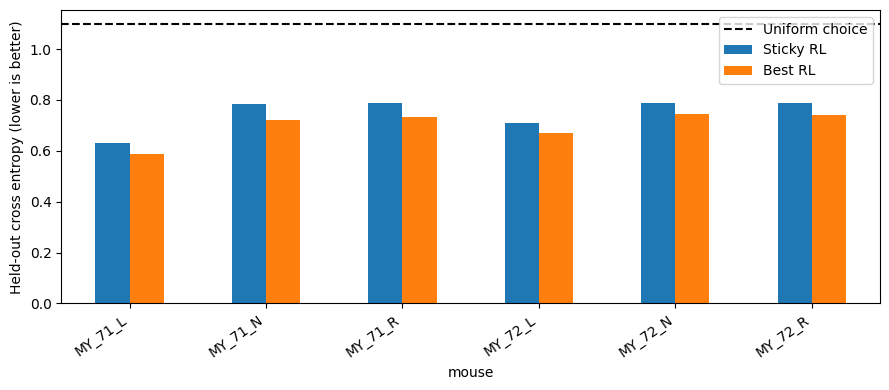

In [45]:
comparison = pd.DataFrame(best_mouse_comparison).set_index("mouse")

ax = comparison[
    ["sticky_cross_entropy", "best_cross_entropy"]
].plot.bar(figsize=(9, 4))

ax.axhline(np.log(3), color="black", linestyle="--", label="Uniform choice")
ax.set_ylabel("Held-out cross entropy (lower is better)")
ax.legend(["Uniform choice", "Sticky RL", "Best RL"])
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## Parameter comparison across RL models, per mouse

This section loads the completed per-mouse leave-one-problem-out fits, without retraining. Sticky RL and Best RL are available from the saved runs. Released RL is included if `released_cohort_results` exists after running its optional per-mouse fit cell. The population fit has one shared parameter vector and is not a source of separate per-mouse estimates.

Colors distinguish models; dots show each training-fold estimate and thick bars their unweighted means. Fold estimates share training data: their spread and the exported `fold_sd` are **not confidence intervals**. Black outlines mark optimizer-bound flags. Missing parameters are omitted, not plotted as fitted zeros. Failed fits are reported and excluded; `n_folds` in the table shows the actual number included.

Sticky RL's stickiness `alpha` is displayed alongside `kappa` as previous-action bias. Both enter logits multiplied by beta, but Sticky RL only allows nonnegative stickiness (0–3), whereas the other models allow switching/repetition biases (−1–1). Learning rate and forgetting have ranges 0–1. Fitting bounds differ across models, so inspect boundary flags alongside values.

**Best RL identifiability:** in the six-parameter written-paper model, choices identify the combination `bias − learning_rate × q_init`, not bias and initial value independently. Their separate plotted values can change without changing predictions; they should not be interpreted as distinct mouse traits. Means across folds are descriptive summaries, not a new model fitted to all problems.

The beta panel uses a symmetric-log scale (linear near zero) because Best RL estimates span a much wider range than Sticky RL.


In [ ]:
# Load completed per-mouse fits without rerunning optimization.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

parameter_repo = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                      if (p / "src/agents/cohort_fitting.py").exists())
parameter_saved_best_dirs = {'MY_71_L': 'results/cohort_01_parameter_fitting/best_rl/4aa772ac8a3e', 'MY_71_N': 'results/cohort_01_parameter_fitting/best_rl/0cd1721fb55e', 'MY_71_R': 'results/cohort_01_parameter_fitting/best_rl/b73c83b8fed6', 'MY_72_L': 'results/cohort_01_parameter_fitting/best_rl/e9a34eb709b9', 'MY_72_N': 'results/cohort_01_parameter_fitting/best_rl/9c70dd461950', 'MY_72_R': 'results/cohort_01_parameter_fitting/best_rl/d55ed84883a5'}
parameter_sources = {}
parameter_sources["Sticky RL"] = pd.read_csv(parameter_repo /
    "results/cohort_01_parameter_fitting/combined_with_MY_71_N_six_folds/fold_results.csv")
if "best_cohort_folds" in globals():
    parameter_sources["Best RL"] = best_cohort_folds.copy()
else:
    parameter_sources["Best RL"] = pd.concat([
        pd.read_csv(parameter_repo / directory / "fold_results.csv")
        for directory in parameter_saved_best_dirs.values()
    ], ignore_index=True)
# Pooled population estimates are deliberately not presented as per-mouse fits.
if "released_cohort_results" in globals() and len(released_cohort_results):
    parameter_sources["Released RL"] = released_cohort_results.copy()
else:
    print("Released RL omitted: no per-mouse results loaded. Run its optional per-mouse fitting cell to include it.")

parameter_records = []
for model, frame in parameter_sources.items():
    if frame.duplicated(["mouse", "held_out_problem"]).any():
        raise ValueError(f"Duplicate mouse/problem fits in {model}; choose one experiment.")
    failed = int((~frame.success.eq(True)).sum())
    print(f"{model}: {int(frame.success.eq(True).sum())} successful folds; {failed} failed folds excluded.")
    frame = frame.loc[frame.success.eq(True)].copy()
    if model == "Sticky RL":
        frame = frame.rename(columns={"alpha": "kappa", "at_bound_alpha": "at_bound_kappa"})
    for parameter in ["learning_rate", "beta", "kappa", "forgetting", "bias", "q_init"]:
        if parameter not in frame:
            continue  # A fixed/absent parameter is not a fitted estimate.
        for _, row in frame.iterrows():
            parameter_records.append(dict(model=model, mouse=row.mouse,
                held_out_problem=int(row.held_out_problem), parameter=parameter,
                value=float(row[parameter]), at_bound=bool(row.get(f"at_bound_{parameter}", False))))
parameter_comparison_long = pd.DataFrame(parameter_records)
parameter_comparison_summary = parameter_comparison_long.groupby(
    ["model", "mouse", "parameter"], as_index=False
).agg(mean=("value", "mean"), fold_sd=("value", "std"),
      n_folds=("value", "size"), n_at_bound=("at_bound", "sum"))
parameter_export = parameter_repo / "results/cohort_01_parameter_fitting/model_parameter_comparison"
parameter_export.mkdir(parents=True, exist_ok=True)
parameter_comparison_long.to_csv(parameter_export / "fold_parameters.csv", index=False)
parameter_comparison_summary.to_csv(parameter_export / "parameter_summary.csv", index=False)

parameter_model_order = [m for m in ["Sticky RL", "Released RL", "Best RL"] if m in parameter_sources]
parameter_model_colors = {"Sticky RL": "#2878B5", "Released RL": "#E69F00", "Best RL": "#A64B89"}
parameter_mice = sorted(parameter_comparison_long.mouse.unique())
parameter_specs = [("learning_rate", "Learning rate"), ("beta", "Inverse temperature β"),
                   ("kappa", "Previous-action bias (α / κ)"),
                   ("forgetting", "Forgetting rate"), ("bias", "Update bias b*"),
                   ("q_init", "Initial action value Qinit*")]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (parameter, title) in zip(axes.flat, parameter_specs):
    for model_index, model in enumerate(parameter_model_order):
        offset = (model_index-(len(parameter_model_order)-1)/2)*.28
        for mouse_index, mouse in enumerate(parameter_mice):
            rows = parameter_comparison_long.loc[
                parameter_comparison_long.model.eq(model)
                & parameter_comparison_long.mouse.eq(mouse)
                & parameter_comparison_long.parameter.eq(parameter)
            ].sort_values("held_out_problem")
            if rows.empty:
                continue
            xs = mouse_index + offset + np.linspace(-.055, .055, len(rows))
            ax.scatter(xs, rows.value, color=parameter_model_colors[model], alpha=.55, s=24)
            boundary = rows.at_bound.to_numpy()
            ax.scatter(xs[boundary], rows.value.to_numpy()[boundary], facecolors="none",
                       edgecolors="black", linewidths=.7, s=35)
            ax.plot([mouse_index+offset-.09, mouse_index+offset+.09], [rows.value.mean()]*2,
                    color=parameter_model_colors[model], linewidth=3)
    available = parameter_comparison_long.loc[parameter_comparison_long.parameter.eq(parameter), "model"].unique()
    ax.set_title(title + (f" — {available[0]} only" if len(available)==1 else ""), fontsize=11)
    ax.set_xticks(range(len(parameter_mice)), parameter_mice, rotation=35, ha="right")
    ax.set_ylabel("Fitted value")
    ax.set_xlim(-.6, len(parameter_mice)-.4)
    if parameter in ("learning_rate", "forgetting"):
        ax.set_ylim(-.03, 1.03)
    if parameter == "beta":
        ax.set_yscale("symlog", linthresh=0.1)
        ax.set_ylim(bottom=0)
        ax.set_ylabel("Fitted β (symlog scale)")
    if parameter in ("kappa", "bias", "q_init"):
        ax.axhline(0, color="gray", linewidth=.7, linestyle=":")
    ax.grid(axis="y", alpha=.18)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("RL parameter estimates across mice and models", fontsize=17, y=.985)
handles = [Line2D([], [], color=parameter_model_colors[m], marker="o", label=m) for m in parameter_model_order]
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(.5, .955), ncol=3, frameon=False)
fig.text(.5, .045, "Dots: training-fold estimates · bars: fold means · black outlines: bound flags. Fold spread is not a confidence interval.", ha="center", fontsize=10)
fig.text(.5, .018, "* Best RL bias and Qinit are not separately identifiable; interpret their individual values cautiously.", ha="center", fontsize=10)
fig.subplots_adjust(top=.87, bottom=.16, hspace=.65, wspace=.30)
for extension in ("png", "pdf"):
    fig.savefig(parameter_export / f"parameters_by_mouse_and_model.{extension}", dpi=170, bbox_inches="tight")
plt.show()
display(parameter_comparison_summary)
print(f"Figures and parameter tables saved to {parameter_export}")


## Effective reward and action-history effects across models

These plots combine parameters **within each fitted fold**, then summarize across folds. They help compare behavioral effects when small learning rates are compensated by large inverse temperatures.

- **Immediate reward effect:** `beta × (1 − forgetting) × learning_rate`. Holding the prior state and chosen action fixed, one extra delivered reward pulse changes that action's next-choice logit by this amount. It is also the change in its log odds relative to an unchosen action; it is not a probability change.
- **Forgetting:** the fraction of each value's displacement from `q_init` removed per update. Sticky RL fixes this to zero; its zero markers are fixed model settings, not estimated parameters.
- **Previous-action bonus:** `beta × stickiness`, where stickiness is `alpha` for Sticky RL and `kappa` for the other models. Positive values directly favor repeating the previous action; negative values favor switching. This is the reward-independent contribution to logits, not the total effect of the previous trial.

Dots are individual training-fold estimates and bars are their means. The overlapping folds are not independent observations, and their spread is not a confidence interval. These combinations clarify scale compensation but do not establish unique parameter identification or summarize every aspect of the model's dynamics. Released RL appears when per-mouse estimates have been loaded in the preceding parameter-comparison section.


In [ ]:
# Run the preceding parameter-comparison cell first, or load its exported table.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

effective_repo = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                      if (p / "src/agents/cohort_fitting.py").exists())
effective_output = effective_repo / "results/cohort_01_parameter_fitting/model_parameter_comparison"
if "parameter_comparison_long" in globals():
    effective_long = parameter_comparison_long.copy()
else:
    effective_long = pd.read_csv(effective_output / "fold_parameters.csv")
effective_folds = effective_long.pivot(
    index=["model", "mouse", "held_out_problem"], columns="parameter", values="value"
).reset_index()
# Zero is a fixed assumption only for Sticky RL, not a replacement for missing fits.
if "forgetting" not in effective_folds:
    effective_folds["forgetting"] = np.nan
effective_folds.loc[effective_folds.model.eq("Sticky RL"), "forgetting"] = 0.
if effective_folds[["beta", "learning_rate", "forgetting", "kappa"]].isna().any().any():
    raise ValueError("Missing required parameters in the per-mouse fit table.")
effective_folds["reward_effect"] = (
    effective_folds.beta * (1-effective_folds.forgetting) * effective_folds.learning_rate
)
effective_folds["previous_action_bonus"] = effective_folds.beta * effective_folds.kappa
effective_metrics = ["reward_effect", "forgetting", "previous_action_bonus"]
effective_summary = effective_folds.groupby(["model", "mouse"])[effective_metrics].agg(["mean", "std", "count"])
effective_folds.to_csv(effective_output / "effective_parameter_folds.csv", index=False)
effective_summary.to_csv(effective_output / "effective_parameter_summary.csv")

models = [m for m in ["Sticky RL", "Released RL", "Best RL"] if m in set(effective_folds.model)]
mice = sorted(effective_folds.mouse.unique())
colors = {"Sticky RL": "#2878B5", "Released RL": "#E69F00", "Best RL": "#A64B89"}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
titles = ["Immediate reward effect: β(1−f)α", "Forgetting rate f", "Previous-action bonus: β × stickiness"]
ylabels = ["Next-choice logit change / reward pulse", "Fraction forgotten per update", "Logit bonus for repeating previous action"]
for ax, metric, title, ylabel in zip(axes, effective_metrics, titles, ylabels):
    for model_index, model in enumerate(models):
        offset = (model_index-(len(models)-1)/2)*.28
        for mouse_index, mouse in enumerate(mice):
            rows = effective_folds.loc[effective_folds.model.eq(model) & effective_folds.mouse.eq(mouse)].sort_values("held_out_problem")
            if rows.empty:
                continue
            center = mouse_index+offset
            if model == "Sticky RL" and metric == "forgetting":
                ax.scatter([center], [0], marker="x", color=colors[model], s=55, zorder=4)
            else:
                ax.scatter(center+np.linspace(-.055, .055, len(rows)), rows[metric], color=colors[model], alpha=.55, s=26)
                ax.plot([center-.09, center+.09], [rows[metric].mean()]*2, color=colors[model], linewidth=3)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(len(mice)), mice, rotation=35, ha="right")
    ax.set_xlim(-.6, len(mice)-.4)
    ax.axhline(0, color="gray", linestyle=":", linewidth=.8)
    if metric == "forgetting":
        ax.set_ylim(-.04, 1.04)
    ax.grid(axis="y", alpha=.18)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Effective RL effects across mice and models", fontsize=16, y=.99)
fig.legend(handles=[Line2D([], [], color=colors[m], marker="o", label=m) for m in models],
           loc="upper center", bbox_to_anchor=(.5, .94), ncol=3, frameon=False)
fig.text(.5, .025, "Dots: fold estimates · bars: means of within-fold combinations · ×: fixed zero forgetting. Fold spread is not a confidence interval.", ha="center", fontsize=9)
fig.subplots_adjust(top=.79, bottom=.26, wspace=.36)
for extension in ("png", "pdf"):
    fig.savefig(effective_output / f"effective_parameters_by_mouse.{extension}", dpi=170, bbox_inches="tight")
plt.show()
display(effective_summary)
